In [131]:
import numpy as np
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats 

### Cargar Datos

In [132]:
FILENAME = "dataset_consolidado.csv"

datapath = os.path.join("..","..","data","clean",FILENAME)
datapath_completo = os.path.join("..","..","data","clean",FILENAME[:-4]+"_complete.csv")
df = pd.read_csv(datapath)
df_completo = pd.read_csv(datapath_completo)

C:\Users\ireni\AppData\Local\Temp\ipykernel_43160\1543507434.py:6: DtypeWarning: Columns (154: Nivel Silo Bagazo Norte (1), 178: KW Trafo 8, 336: Totalizador Bba P1, 337: Totalizador Bba P2, 338: Totalizador Bba P4, 339: Totalizador Bba Envasado, 340: Totalizador Bba P51) have mixed types. Specify dtype option on import or set low_memory=False.
  df_completo = pd.read_csv(datapath_completo)


### Eliminando días en que el totalizador no se reinició a medianoche.

In [133]:
display(df_completo[(df_completo["HORA"] == "00:00:00") & (df_completo["Frio (Kw)"] != 0)]) 
dias_sin_reinicio = df_completo[(df_completo["HORA"] == "00:00:00") & (df_completo["Frio (Kw)"] != 0)]["DIA"]
df = df.drop(index= df[df["DIA"].isin(dias_sin_reinicio)].index)

,Unnamed: 0,DIA,HORA,EE Planta / Hl,EE Elaboracion / Hl,EE Bodega / Hl,EE Cocina / Hl,EE Envasado / Hl,EE Linea 2 / Hl,EE Linea 3 / Hl,EE Linea 4 / Hl,EE Linea 5 / Hl,EE Servicios / Hl,EE Sala Maq / Hl,EE Frio / Hl,EE Aire / Hl,EE CO2 / Hl,EE Caldera / Hl,EE Eflu / Hl,EE Agua / Hl,EE Resto Serv / Hl,EE Resto Planta / Hl,Agua Planta / Hl,Agua Elab / Hl,Agua Bodega / Hl,Agua Cocina / Hl,Agua Envas / Hl,Agua Linea 2/Hl,Agua Linea 3/Hl,Agua Linea 4/Hl,Agua Linea 5/Hl,Agua Servicios/Hl,Agua Planta de Agua/Hl,Produccion Agua / Hl,ET Planta / Hl,ET Elab/Hl,ET Bodega/Hl,ET Cocina/Hl,ET Envasado/Hl,ET Linea 2/Hl,ET Linea 3/Hl,ET Linea 4/Hl,ET Linea 5/Hl,ET Servicios / Hl,Aire Planta / Hl,Aire Elaboracion / Hl,Aire Cocina / Hl,Aire Bodega / Hl,Aire Envasado / Hl,Aire L2 / Hl,Aire L3 / Hl,Aire L4 / Hl,Aire L5 / Hl,Aire Servicios / Hl,Aire Expulsion / Hl,CO 2 / Hl,CO 2 Filtro / Hl,CO 2 linea 3 / Hl,CO 2 Linea 4 / Hl,CO 2 linea 2 / Hl,Agua Lavadora L3 / Hl,Agua Paste L3 / Hl,Meta EE Planta,Meta Agua Planta,Meta ET Planta,Meta Aire Planta,Meta Agua Elab,Meta Agua Bodega,Meta Agua Cocina,Meta Agua Envas,Meta Agua Linea 2,Meta Agua Linea 3,Meta Agua Linea 4,Meta Agua Linea 5,Meta Agua Servicios,Meta Agua Planta de Agua,Meta Produccion Agua,Meta EE Elaboracion,Meta EE Bodega,Meta EE Cocina,Meta EE Envasado,Meta EE Linea 2,Meta EE Linea 3,Meta EE Linea 4,Meta EE Linea 5,Meta EE Servicios,Meta EE Sala Maq,Meta EE Frio,Meta EE Aire,Meta EE CO2,Meta EE Caldera,Meta EE Eflu,Meta EE Agua,Meta EE Resto Serv,Meta EE Resto Planta,Meta ET Elab,Meta ET Bodega,Meta ET Cocina,Meta ET Envasado,Meta ET Linea 2,Meta ET Linea 3,Meta ET Linea 4,Meta ET Linea 5,Meta ET Servicios,Meta Aire Elaboracion,Meta Aire Cocina,Meta Aire Bodega,Meta Aire Envasado,Meta Aire L2,Meta Aire L3,Meta Aire L4,Meta Aire L5,Meta Aire Servicios,Hl de Mosto,Hl Cerveza Cocina,Hl Producido Bodega,Hl Cerveza Filtrada,Hl Cerveza Envasada,Hl Cerveza L2,Hl Cerveza L3,Hl Cerveza L4,Hl Cerveza L5,Cocimientos Diarios,Hl de Mosto Copia,HL Mosto Budweiser,HL Mosto Tecate,HL Mosto Local,HL Mosto Heineken,HL Mosto Negra,HL Mosto Fuerte,HL Mosto Indio,HL Mosto Palermo,HL Mosto Bieckert,HL Mosto Malta,HL Mosto Amstel,HL Mosto Sol,HL Mosto Frost,HL Mosto Miller,HL Mosto IPA,HL Mosto APA,HL Mosto Roja,HL Mosto Isenbeck,HL Mosto Golden,HL Mosto Amstel Lager,Hl Mosto Cautiva Roja,Hl Mosto Cautiva Torrontes,Hl Mosto Cautiva Blend,Hl Mosto Bieckert Urbana,Hl Mosto Bieckert BAPA,Hl Mosto Blue Moon,Hl Reserva 7,Hl Reserva 8,HL Cerveza Sin Diliuir A90,HL Cerceza Sin Diluir A190,Nivel Silo Bagazo Norte (1),Nivel Silo Bagazo Sur (2),Nivel Tk Restos Lev,Planta (Kw),Elaboracion (Kw),Bodega (Kw),Cocina (Kw),Envasado (Kw),Linea 2 (Kw),Linea 3 (Kw),Linea 4 (Kw),Servicios (Kw),Sala Maq (Kw),Aire (Kw),Calderas (Kw),Efluentes (Kw),Frio (Kw),Pta Agua / Eflu (Kw),Prod Agua (Kw),Resto Serv (Kw),Restos Planta (Kw),KW Gral Planta,KW Trafo 4,KW Trafo 5,KW Trafo 8,KW Trafo 11,KW Trafo 12,KW Linea 2,KW Mycom 1,KW Mycom 2,KW Mycom 3,KW Mycom 4,KW Mycom 5,KW Mycom 6,KW Mycom 7,KW Trafo 9,KW Trafo 10,KW Cocina,Kw Molino,KW Linea 3 y 4,KW Linea 3,KW Linea 4,KW Servicio L2,KW Planta de Agua,Kw llum/Serv L2,Kw Casona,KW Laboratorio,Kw Admininistracion,KW Pta Agua/Log,KW Bba Glicol Sala MAq,KW Comp Kaeser,KW Iluminacion L3,KW Iluminacion L4,KW Ilum Dep L3/L4,KW Cond 5. 6 y 9,KW Cond 7. 8 y 11,KW Cond 11. 12 y 13,KW Bba Glicol Bod,KW CO2,KW Secador Kaeser,KW Caldera 3,KW Caldera 4,KW Filtr Carbon,KW Atlas 3,KW Toma Agua,KW Enfr Agua Cocina,KW Enfluentes Coc,KW Enfluente Efl,KW Enfluentes Hidr,KW Obrador Contratistas,Kw Compresores Aire,Kw Linea Barriles,Agua Planta (Hl),Agua Elaboracion (Hl),Agua Bodega (Hl),Agua Cocina (Hl),Agua Dilucion (Hl),Agua Envasado (Hl),Agua Servicios (Hl),Planta de agua (Hl),Produccion (Hl),Red L1 y L2,FC L1 y L2,FC Lavadora L2,Red L3,FC Lavadora L3,Red Paste L4,FC Barriles,Agua Paste L3,Agua Lavadora L3,Agua Cond Evaporativos,Agua Calderas,Agua Efluentes,Agua CO2,Red Paste L1,FC Linea 3,Rinser,Red Barriles

In [134]:
df_completo['DIA'] = pd.to_datetime(df_completo['DIA'])
df_completo['HORA'] = pd.to_datetime(df_completo['HORA'], format='%H:%M:%S').dt.time
df_temp = df_completo.groupby('DIA').last().reset_index()
hora_cierre = pd.to_datetime('23:59:00').time()
df_diario = df_temp[df_temp['HORA'] == hora_cierre].copy()


dias_eliminados = len(df_temp) - len(df_diario)
print(f"Se eliminaron {dias_eliminados} días incompletos que no llegaron a las 23:59.")

fecha_siguiente = df_diario["DIA"].shift(-1)
fecha_actual = df_diario["DIA"]
diferencia_dia_siguiente = fecha_siguiente - fecha_actual
indices_a_borrar = df_diario.index[diferencia_dia_siguiente > pd.Timedelta(days=1)]
df_diario = df_diario.drop(index=indices_a_borrar)
df_diario['target_Frio_kW_next'] = df_diario['Frio (Kw)'].shift(-1)

df_diario = df_diario.dropna(subset=['target_Frio_kW_next']).copy()

df_completo = df_diario.copy()
df_completo["DIA"] = df_completo["DIA"].astype(str)
df_completo = df_completo.drop(index= df_completo[df_completo["DIA"].isin(dias_sin_reinicio)].index)

Se eliminaron 5 días incompletos que no llegaron a las 23:59.


C:\Users\ireni\AppData\Local\Temp\ipykernel_43160\4021204731.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_temp = df_completo.groupby('DIA').last().reset_index()


In [135]:
print(f"dimension del dataset (nuestras features): {df.shape}")
print(f"dimension del dataset completo: {df_completo.shape}")
display(df.head)
display(df_completo.head)

dimension del dataset (nuestras features): (1162, 39)
dimension del dataset completo: (1162, 387)


<bound method NDFrame.head of              DIA  KW Mycom 1  KW Mycom 2  KW Mycom 3  KW Mycom 4  KW Mycom 5  \
0     2020-07-01           0      3600.0         0.0           0         0.0   
1     2020-07-02         701      5848.0      1362.0        2238         0.0   
2     2020-07-03         328      5980.0      5356.0        3321         0.0   
3     2020-07-04           0      6040.0      1407.0        5029         0.0   
4     2020-07-05           0      6381.0      2043.0        5501         0.0   
...          ...         ...         ...         ...         ...         ...   
1159  2023-10-20        3549         0.0         0.0         576      1279.0   
1160  2023-10-21         129         0.0      1736.0           0      1954.0   
1161  2023-10-22           0         0.0         0.0           0      4094.0   
1162  2023-10-23           0         0.0         0.0           0      4605.0   
1163  2023-10-24         554         0.0         0.0         243      4236.0   

      KW 

<bound method NDFrame.head of              DIA  Unnamed: 0      HORA  EE Planta / Hl  EE Elaboracion / Hl  \
0     2020-07-01          24  23:59:00      642.727209            47.145349   
1     2020-07-02          49  23:59:00        7.767254             0.769609   
2     2020-07-03          74  23:59:00        8.801205             0.862593   
3     2020-07-04          99  23:59:00        5.175639             0.439225   
4     2020-07-05         124  23:59:00        7.924665             0.802365   
...          ...         ...       ...             ...                  ...   
1183  2023-10-20       29566  23:59:00             NaN                  NaN   
1184  2023-10-21       29591  23:59:00             NaN                  NaN   
1185  2023-10-22       29616  23:59:00        7.274196             0.768547   
1186  2023-10-23       29641  23:59:00       58.805087             4.777436   
1187  2023-10-24       29666  23:59:00       33.526177             3.299732   

      EE Bodega / Hl 

### Descriptiva de cada variable

In [136]:
pd.set_option("display.max_columns", None)
display(df.describe(include='all'))    

,DIA,KW Mycom 1,KW Mycom 2,KW Mycom 3,KW Mycom 4,KW Mycom 5,KW Mycom 6,KW Mycom 7,EE Frio / Hl,KW Bba Glicol Sala MAq,KW Bba Glicol Bod,KW Enfr Agua Cocina,Hl de Mosto,Hl Producido Bodega,Hl Cerveza Filtrada,Hl Cerveza Envasada,Hl Cerveza Cocina,Elaboracion (Kw),Bodega (Kw),Envasado (Kw),Servicios (Kw),Frio (Kw),Agua Planta (Hl),Agua Helada Cocina,Glicol Paste L3,Temp Tq Intermedio,Gas Planta (Mj),Vapor Elaboracion (Kg),Totalizador_Bodega,Totalizador_Tq_Pulmon,Tot Fermantacion_Cocina,Tot Reposo Inferior,Tot Reposo Superior,Tot Trasiego,Tot A10/20,Tot A40/240/50/60/Centec/Filtro,Tot A130/330/430,"Tot L3, L4 y Planta de CO2",target_Frio_kW_next
count,1162,1.162000e+03,1162.000000,1162.000000,1.162000e+03,1162.000000,1162.000000,1.162000e+03,1141.000000,1162.000000,1162.000000,1162.000000,1162.000000,1162.000000,1162.000000,1162.000000,1162.000000,1162.000000,1162.000000,1.162000e+03,1162.000000,1.162000e+03,1162.000000,1162.000000,1162.000000,1162.000000,1162.000000,1162.000000,1162.000000,1162.000000,598.000000,598.000000,598.000000,1094.000000,565.000000,565.000000,565.000000,462.000000,1.162000e+03
unique,1162,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2020-07-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,1.264384e+04,3702.012048,2632.876936,6.633366e+03,1590.826162,1770.324441,1.099112e+04,6.503811,1288.932874,2617.527539,3.519793,5456.887263,8527.883447,7874.685026,8472.197074,8583.569819,6947.767160,5956.973916,2.819966e+13,38708.533133,4.628377e+04,32152.221960,1070.214931,0.012909,19.695284,528692.855202,57828.420256,3442.883121,11729.003442,1582.090167,5332.412207,1746.867441,1527.136026,3011.028566,2104.995770,5787.851142,3580.276404,4.627198e+04
std,NaN,2.422037e+05,2860.859761,2119.311040,1.189627e+05,2133.268319,1525.133296,2.592448e+05,50.191657,482.256706,555.491775,10.401585,2770.183161,3469.879958,3565.423156,4164.597110,4647.121861,1938.383404,1827.605875,9.612733e+14,9865.037367,3.742008e+05,8332.858298,2659.211620,0.354595,4.781779,149623.713413,30508.599517,1807.754326,4615.448755,8099.587467,2450.668809,13664.285870,8958.615307,2680.144009,1110.392308,1369.046246,4933.896257,3.742015e+05
min,NaN,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-672.000000,-6247.000000,3.180000e+02,8093.000000,2.310000e+03,4963.800000,0.000000,0.000000,-3.000000,4440.315000,2608.570000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,518.630000,2275.780000,3.750000,2.310000e+03
25%,NaN,0.000000e+00,0.000000,485.000000,0.000000e+00,0.000000,91.250000,0.000000e+00,2.194070,878.250000,2267.250000,0.000000,3650.250000,5963.450000,5731.250000,5789.000000,5503.815000,5709.500000,4847.625000,9.798750e+03,31417.250000,1.794525e+04,26569.925000,0.000000,0.000000,18.177500,445903.269760,28055.975000,2301.030000,8801.250000,606.912500,3890.370000,2.200000,635.847500,0.000000,1228.130000,4804.010000,474.420000,1.794525e+04
50%,NaN,2.535000e+02,5496.000000,2494.000000,7.755000e+02,0.000000,1638.500000,4.545500e+03,2.666412,1208.000000,2693.500000,0.000000,6451.500000,9147.687500,8288.500000,9328.000000,9339.500000,7138.750000,6078.875000,1.635700e+04,39030.500000,2.375450e+04,33513.150000,0.000000,0.000000,20.340000,541444.712518,62130.830000,3484.925000,12656.000000,944.905000,5595.750000,12.305000,1206.080000,4357.710000,1861.310000,5565.940000,1161.615000,2.375450e+04
75%,NaN,5.706500e+03,6110.250000,4444.000000,3.070500e+03,3464.000000,3022.750000,5.804500e+03,3.397722,1736.000000,3018.000000,0.000000,7554.750000,11252.975000,10693.

## EDA Univariado

### Valores nulos: 

In [137]:
print("Porcentaje de valores nulos por columna: (el resto no tiene valores nulos)")
print(df[df.columns[df.isna().any()]].isna().sum().sort_values(ascending=False)/df.shape[0]*100)

Porcentaje de valores nulos por columna: (el resto no tiene valores nulos)
Tot L3, L4 y Planta de CO2         60.240964
Tot A10/20                         51.376936
Tot  A130/330/430                  51.376936
Tot A40/240/50/60/Centec/Filtro    51.376936
Tot Reposo Inferior                48.537005
Tot Fermantacion_Cocina            48.537005
Tot  Reposo Superior               48.537005
Tot  Trasiego                       5.851979
EE Frio / Hl                        1.807229
dtype: float64


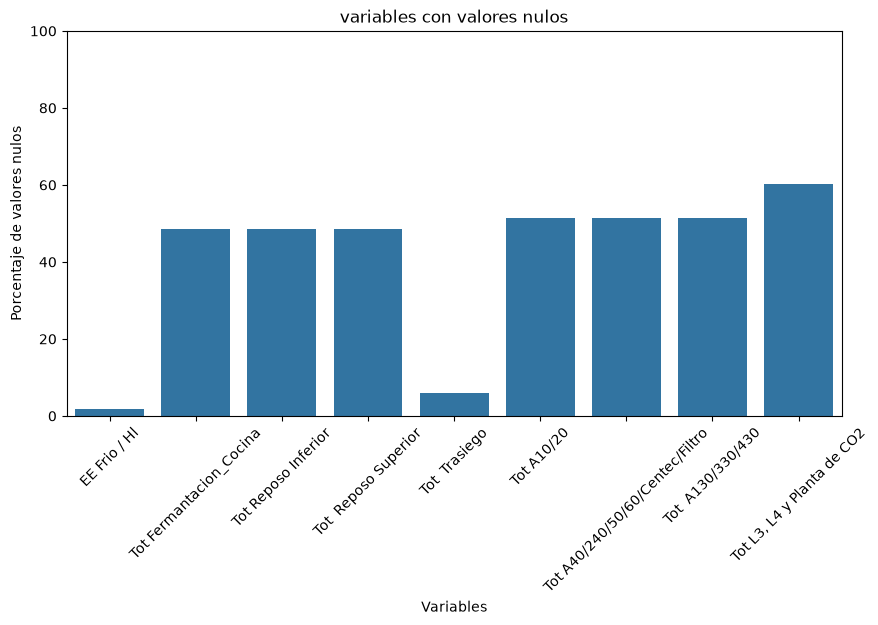

In [138]:
nulos = df.isna().sum()/df.shape[0]*100
plt.figure(figsize=(10,5))
sns.barplot(x=df.columns[nulos>0],y=nulos[nulos>0])
plt.xticks(rotation=45)
plt.title("variables con valores nulos")
plt.ylabel("Porcentaje de valores nulos")
plt.xlabel("Variables")
plt.ylim(0,100)
plt.show()

### Valores con cero

Número de valores cero por columna:


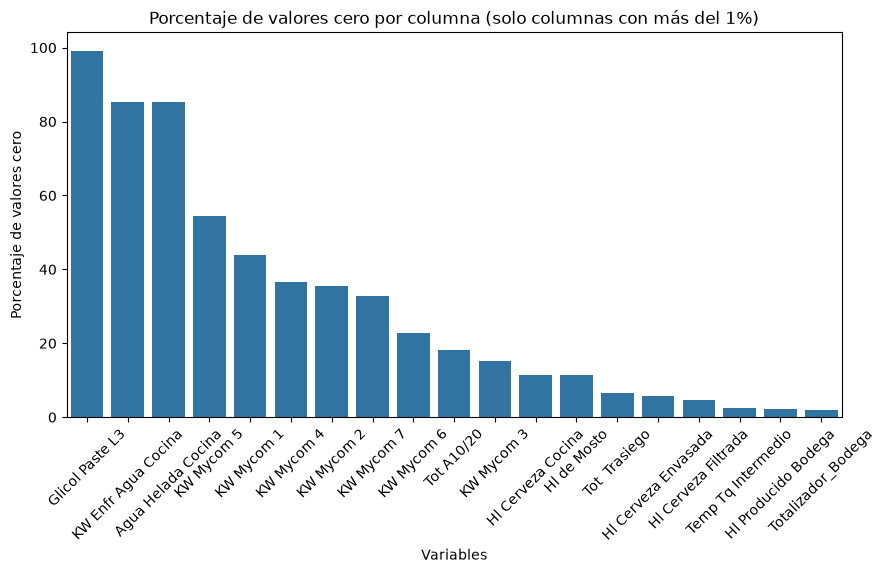

In [139]:
print("Número de valores cero por columna:")
cant_ceros = (df==0).sum().sort_values(ascending=False)/df.shape[0]*100
plt.figure(figsize=(10,5))
sns.barplot(x=cant_ceros.index[cant_ceros>1],y=cant_ceros.values[cant_ceros>1])
plt.xticks(rotation=45)
plt.title("Porcentaje de valores cero por columna (solo columnas con más del 1%)")
plt.ylabel("Porcentaje de valores cero")
plt.xlabel("Variables")
plt.show()

Porcentaje de valores cero en Kw Mycom Mean: 0.34%
Las filas donde se producen outliers extremos:


,DIA,KW Mycom 1,KW Mycom 2,KW Mycom 3,KW Mycom 4,KW Mycom 5,KW Mycom 6,KW Mycom 7,EE Frio / Hl,KW Bba Glicol Sala MAq,KW Bba Glicol Bod,KW Enfr Agua Cocina,Hl de Mosto,Hl Producido Bodega,Hl Cerveza Filtrada,Hl Cerveza Envasada,Hl Cerveza Cocina,Elaboracion (Kw),Bodega (Kw),Envasado (Kw),Servicios (Kw),Frio (Kw),Agua Planta (Hl),Agua Helada Cocina,Glicol Paste L3,Temp Tq Intermedio,Gas Planta (Mj),Vapor Elaboracion (Kg),Totalizador_Bodega,Totalizador_Tq_Pulmon,Tot Fermantacion_Cocina,Tot Reposo Inferior,Tot Reposo Superior,Tot Trasiego,Tot A10/20,Tot A40/240/50/60/Centec/Filtro,Tot A130/330/430,"Tot L3, L4 y Planta de CO2",target_Frio_kW_next,Kw Mycom Mean
293,2021-04-30,5540000,6641.0,3380.0,3151,0.0,4343.0,6728.0,712.156289,1109.0,2894.0,0.0,6477.0,7825.25,7322.0,5500.0,10150.5,8077.5,7430.5,9.761000e+03,48013.5,5572801.0,31941.5,0.0,0.0,23.42,400652.608700,66739.03,3701.53,11042.0,1071.75,9580.25,1.73,2062.52,NaN,NaN,NaN,NaN,29361.0,7.948919e+05
378,2021-07-28,5681,4916.0,5060.0,2870006,4397.0,1030.0,1715.0,3.953632,854.0,2376.0,0.0,3225.0,7268.00,12998.0,11311.0,3225.0,8704.5,9506.0,1.841700e+04,42037.0,2900770.0,42321.0,0.0,0.0,21.61,518421.823076,48749.63,4434.94,17319.0,1212.66,5104.97,177.37,1134.03,NaN,NaN,NaN,NaN,30962.0,4.132579e+05
406,2021-08-25,1350,6654.0,6528.0,2870000,4621.0,2696.0,6725.0,251.376396,927.0,2357.0,0.0,6862.0,11554.45,11872.0,13159.0,9949.9,8907.0,7731.0,2.048500e+04,55342.5,2907122.0,40352.1,0.0,0.0,20.56,683409.504252,89754.50,7624.63,20209.0,926.96,7091.53,6.80,1053.91,NaN,NaN,NaN,NaN,36002.0,4.140820e+05
495,2021-11-28,6130209,6011.0,3573.0,0,5460.0,3009.0,1582.0,735.342168,1138.0,2908.0,0.0,4988.0,8368.70,13092.0,7759.0,8978.4,6525.5,5134.5,3.276800e+16,41092.0,6155928.0,32801.9,0.0,0.0,15.49,616603.452796,84756.63,4845.31,12839.0,793.69,9968.75,0.75,1457.67,NaN,NaN,NaN,NaN,17838.0,8.785491e+05
575,2022-02-18,0,5648.0,5412.0,0,1971.0,3276.0,8840000.0,952.992406,1036.0,3219.0,0.0,4547.0,9297.20,11810.0,13117.0,5477.4,6937.5,13305.5,1.287400e+04,38010.0,8861470.0,35019.9,0.0,0.0,15.06,645559.207200,21072.84,5034.13,14212.0,1259.44,1927.97,5064.13,1673.20,NaN,NaN,NaN,NaN,16649.0,1.265187e+06


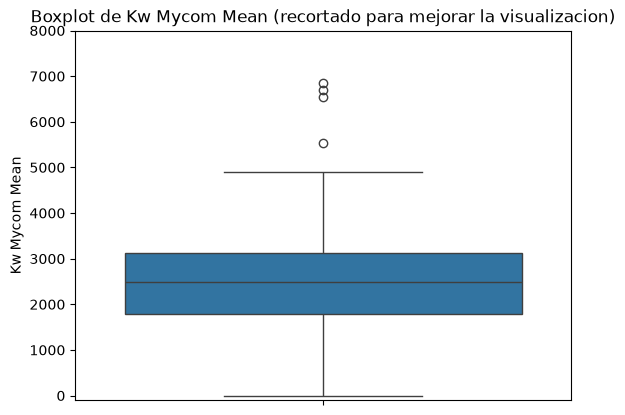

In [140]:
#Muchos de los valores de Mycom son 0, por lo que se calcula la media de las columnas de Mycom.
#La presencia de outliers imposibilita la correcta visualización del boxplot
mycoms = df.columns[df.columns.str.contains("Mycom")]

df["Kw Mycom Mean"] = df.loc[:, df.columns.str.contains("Mycom")].mean(axis=1)
sns.boxplot(df, y="Kw Mycom Mean")
plt.ylim(-100,8000) 
plt.title("Boxplot de Kw Mycom Mean (recortado para mejorar la visualizacion)")
cant_ceros = (df["Kw Mycom Mean"]==0).sum()/df.shape[0]*100
print(f"Porcentaje de valores cero en Kw Mycom Mean: {cant_ceros:.2f}%")
print("Las filas donde se producen outliers extremos:")
display(df[df["Kw Mycom Mean"] > 0.3e6])

In [141]:
# dropeo de las mycoms, nos quedamos con la mean
df = df.drop(columns=mycoms, errors= "ignore")
df.columns

Index(['DIA', 'EE Frio / Hl', 'KW Bba Glicol Sala MAq', 'KW Bba Glicol Bod',
       'KW Enfr Agua Cocina', 'Hl de Mosto', 'Hl Producido Bodega',
       'Hl Cerveza Filtrada', 'Hl Cerveza Envasada', 'Hl Cerveza Cocina',
       'Elaboracion (Kw)', 'Bodega (Kw)', 'Envasado (Kw)', 'Servicios (Kw)',
       'Frio (Kw)', 'Agua Planta (Hl)', 'Agua Helada Cocina',
       'Glicol Paste L3', 'Temp Tq Intermedio', 'Gas Planta (Mj)',
       'Vapor Elaboracion (Kg)', 'Totalizador_Bodega', 'Totalizador_Tq_Pulmon',
       'Tot Fermantacion_Cocina', 'Tot Reposo Inferior',
       'Tot  Reposo Superior', 'Tot  Trasiego', 'Tot A10/20',
       'Tot A40/240/50/60/Centec/Filtro', 'Tot  A130/330/430',
       'Tot L3, L4 y Planta de CO2', 'target_Frio_kW_next', 'Kw Mycom Mean'],
      dtype='str')

### Valores atípicos: Detección con IQR modificado

Index(['EE Frio / Hl', 'KW Bba Glicol Sala MAq', 'KW Bba Glicol Bod',
       'KW Enfr Agua Cocina', 'Hl de Mosto', 'Hl Producido Bodega',
       'Hl Cerveza Filtrada', 'Hl Cerveza Envasada', 'Hl Cerveza Cocina',
       'Elaboracion (Kw)', 'Bodega (Kw)', 'Envasado (Kw)', 'Servicios (Kw)',
       'Frio (Kw)', 'Agua Planta (Hl)', 'Agua Helada Cocina',
       'Glicol Paste L3', 'Temp Tq Intermedio', 'Gas Planta (Mj)',
       'Vapor Elaboracion (Kg)', 'Totalizador_Bodega', 'Totalizador_Tq_Pulmon',
       'Tot Fermantacion_Cocina', 'Tot Reposo Inferior',
       'Tot  Reposo Superior', 'Tot  Trasiego', 'Tot A10/20',
       'Tot A40/240/50/60/Centec/Filtro', 'Tot  A130/330/430',
       'Tot L3, L4 y Planta de CO2', 'target_Frio_kW_next', 'Kw Mycom Mean'],
      dtype='str')

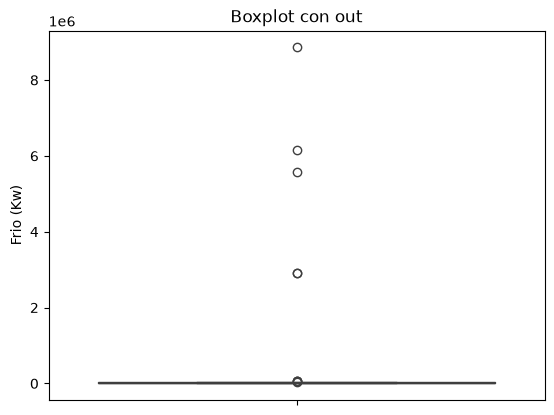

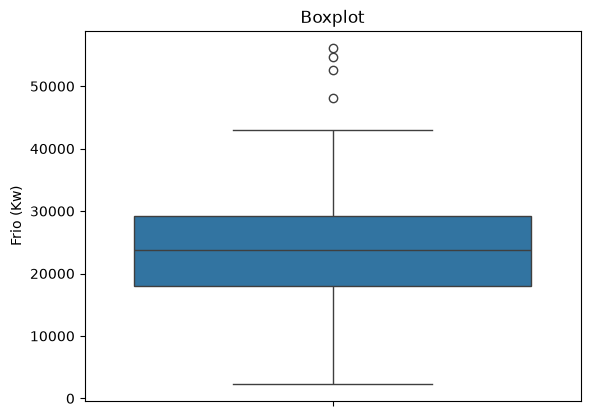

In [142]:
features_sin_dia = df.columns[1:]

for f in features_sin_dia: 
    Q1 = df[f].quantile(0.25)
    Q3 = df[f].quantile(0.75)
    IQR = Q3 - Q1

    #no pusimos 1.5 ya que nos parece muy estricto
    outliers = df[(df[f] < - 3 * IQR + Q1 ) | (df[f] >  3 * IQR + Q3 )].index
    df_temp_outliers = df.drop(index = outliers)


    if f == 'Frio (Kw)':
        plt.figure()
        sns.boxplot(df, y=f) 
        plt.title("Boxplot con out")
        plt.figure()
        sns.boxplot(df_temp_outliers, y=f) 
        plt.title("Boxplot")
    
features_sin_dia

In [143]:
Q1_frio = df["Frio (Kw)"].quantile(0.25)
Q3_frio = df["Frio (Kw)"].quantile(0.75)
IQR_frio = Q3_frio - Q1_frio

#no pusimos 1.5 ya que nos parece muy estricto
outliers = df[(df["Frio (Kw)"] < - 3 * IQR_frio + Q1_frio ) | (df["Frio (Kw)"] >  3 * IQR_frio + Q3_frio )].index
df_sin_frio_outliers = df.drop(index = outliers)


In [144]:
Q1_frio_next = df_sin_frio_outliers["target_Frio_kW_next"].quantile(0.25)
Q3_frio_next = df_sin_frio_outliers["target_Frio_kW_next"].quantile(0.75)
IQR_frio_next = Q3_frio_next - Q1_frio_next

#no pusimos 1.5 ya que nos parece muy estricto
outliers = df_sin_frio_outliers[(df_sin_frio_outliers["target_Frio_kW_next"] < - 3 * IQR_frio_next + Q1_frio_next ) | (df_sin_frio_outliers["target_Frio_kW_next"] >  3 * IQR_frio_next + Q3_frio_next )].index
df_sin_frio_outliers = df_sin_frio_outliers.drop(index = outliers)

### Evolución temporal

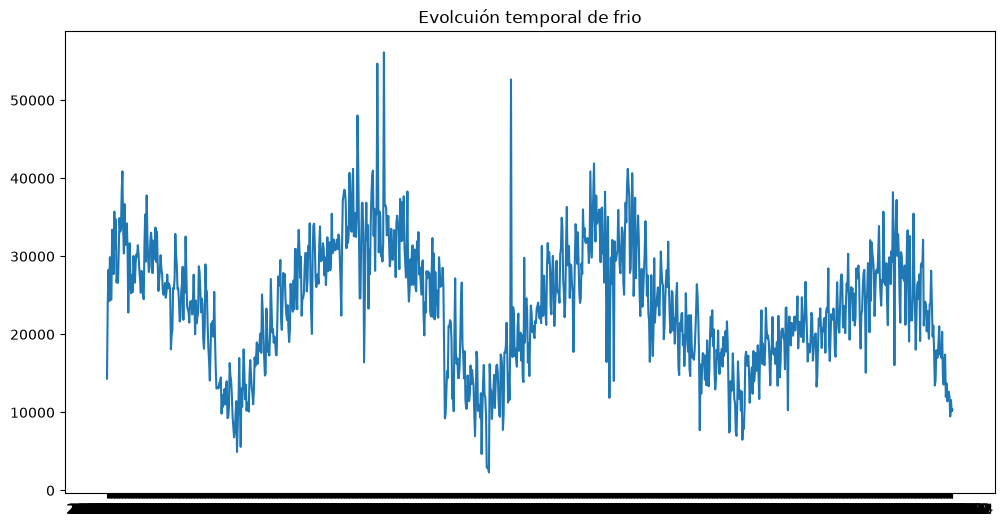

In [145]:
plt.figure(figsize=(12,6))
plt.plot(df_sin_frio_outliers["DIA"], df_sin_frio_outliers["Frio (Kw)"])
plt.title("Evolcuión temporal de frio")
plt.show()

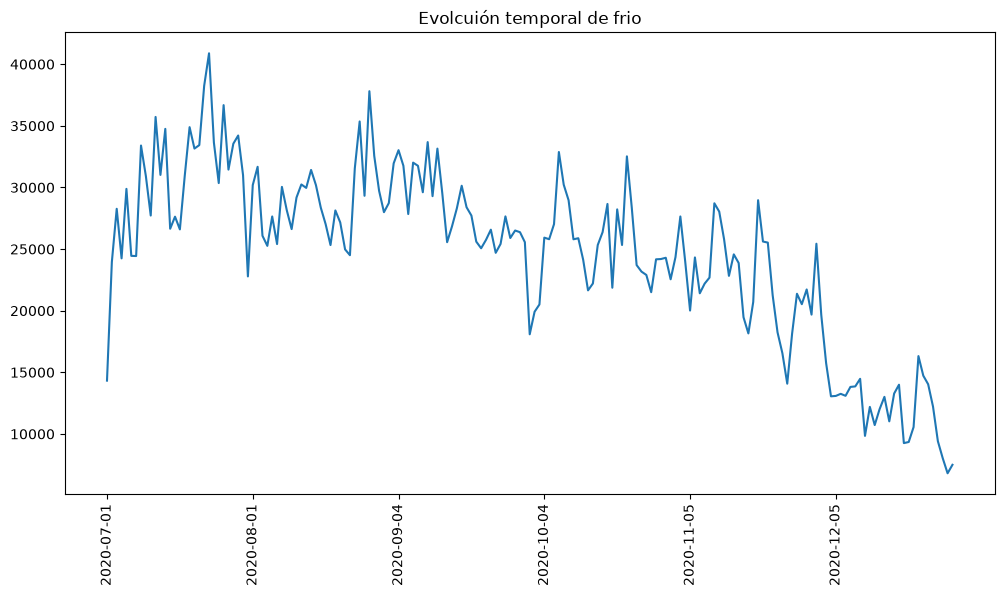

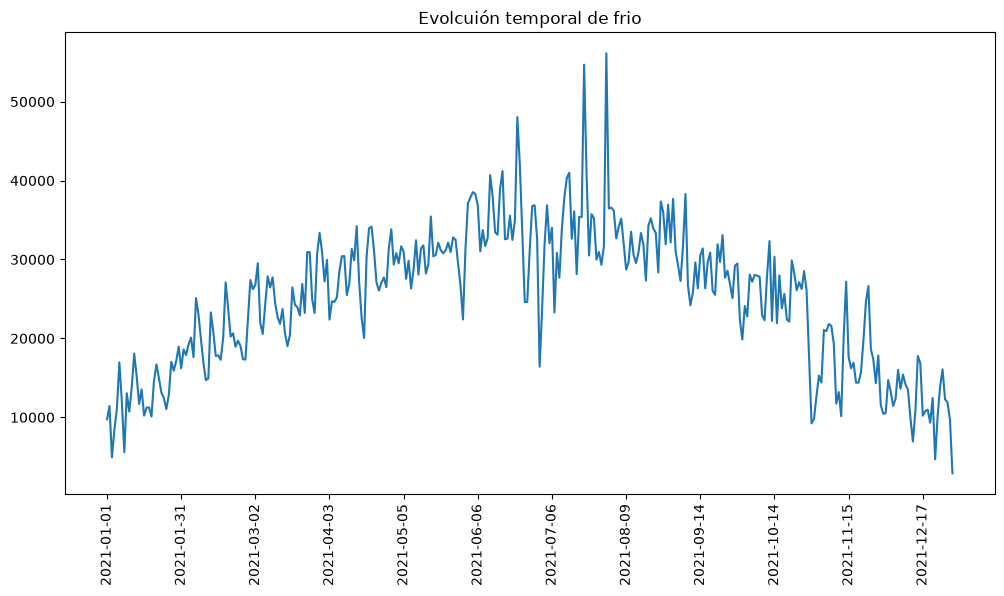

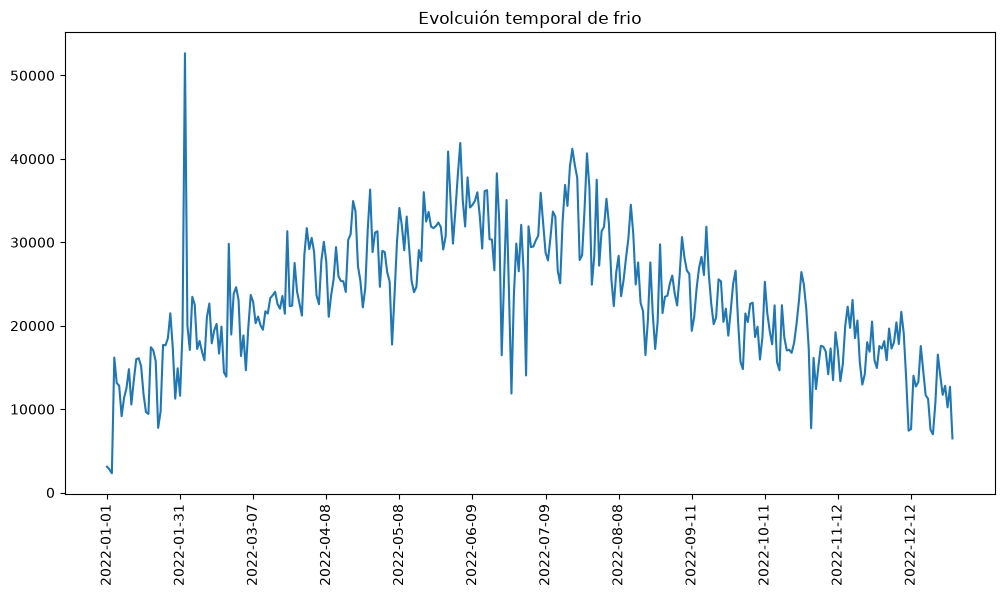

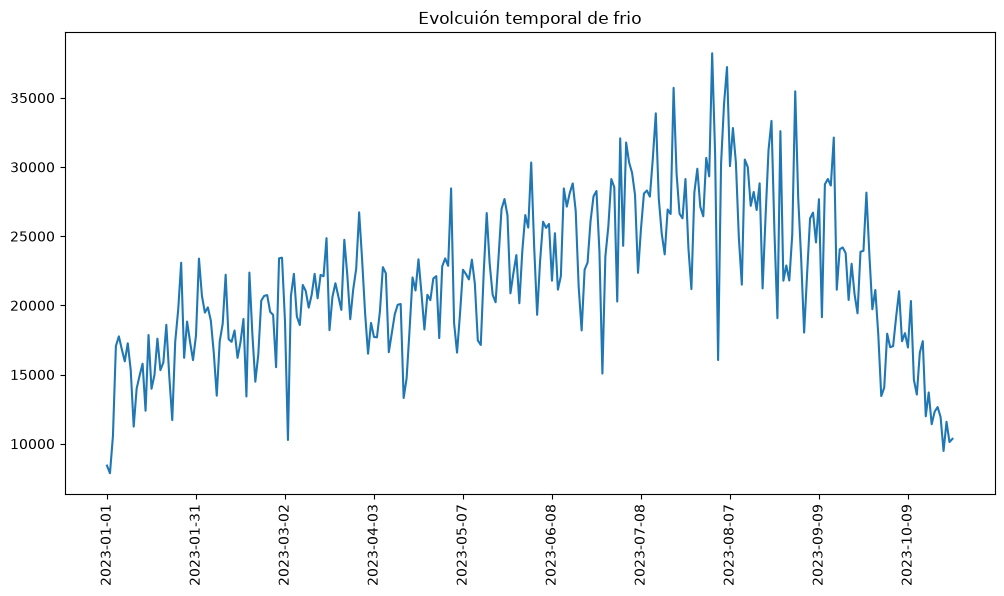

In [146]:
anios = ["2020","2021","2022","2023"]
for anio in anios:
    df_anio = df_sin_frio_outliers[df_sin_frio_outliers["DIA"].str.contains(anio)]
    plt.figure(figsize=(12,6))
    plt.plot(df_anio["DIA"], df_anio["Frio (Kw)"])
    plt.xticks(df_anio["DIA"][::30],rotation=90)
    plt.title("Evolcuión temporal de frio")
    plt.show()

se puede observar estacionariedad

In [147]:
df_sin_frio_outliers["DIA"] = pd.to_datetime(df_sin_frio_outliers["DIA"])
df_sin_frio_outliers["DIA SEMANA"] = df_sin_frio_outliers["DIA"].dt.dayofweek

<Axes: xlabel='DIA SEMANA', ylabel='target_Frio_kW_next'>

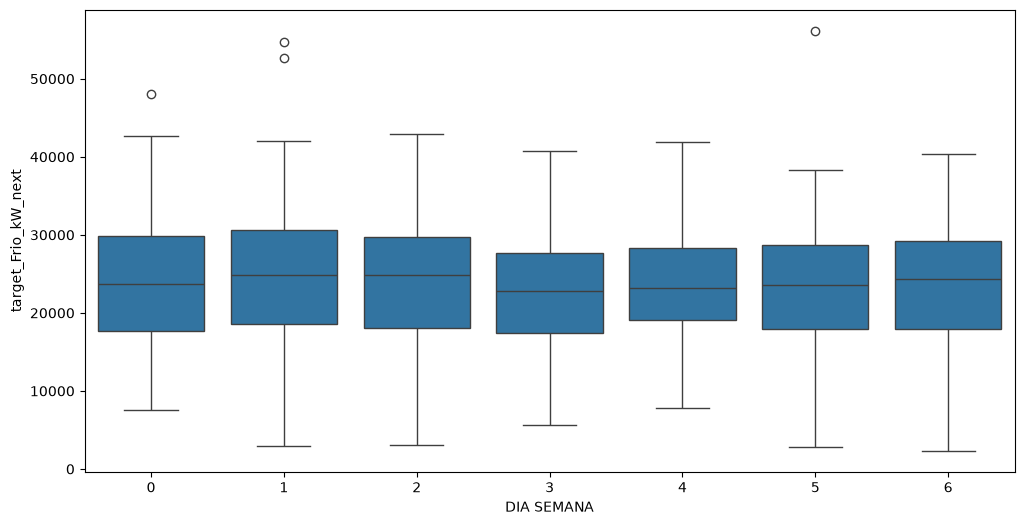

In [148]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_sin_frio_outliers, x="DIA SEMANA",y= "target_Frio_kW_next")


Descartamos la idea de añadir la columna de "DIA SEMANA" ya que no se observa efectos apreciables para cada día o algún día específico.

In [149]:
df_sin_frio_outliers = df_sin_frio_outliers.drop(columns="DIA SEMANA")

## ANÁLISIS DE CORRELACIONES

<Axes: >

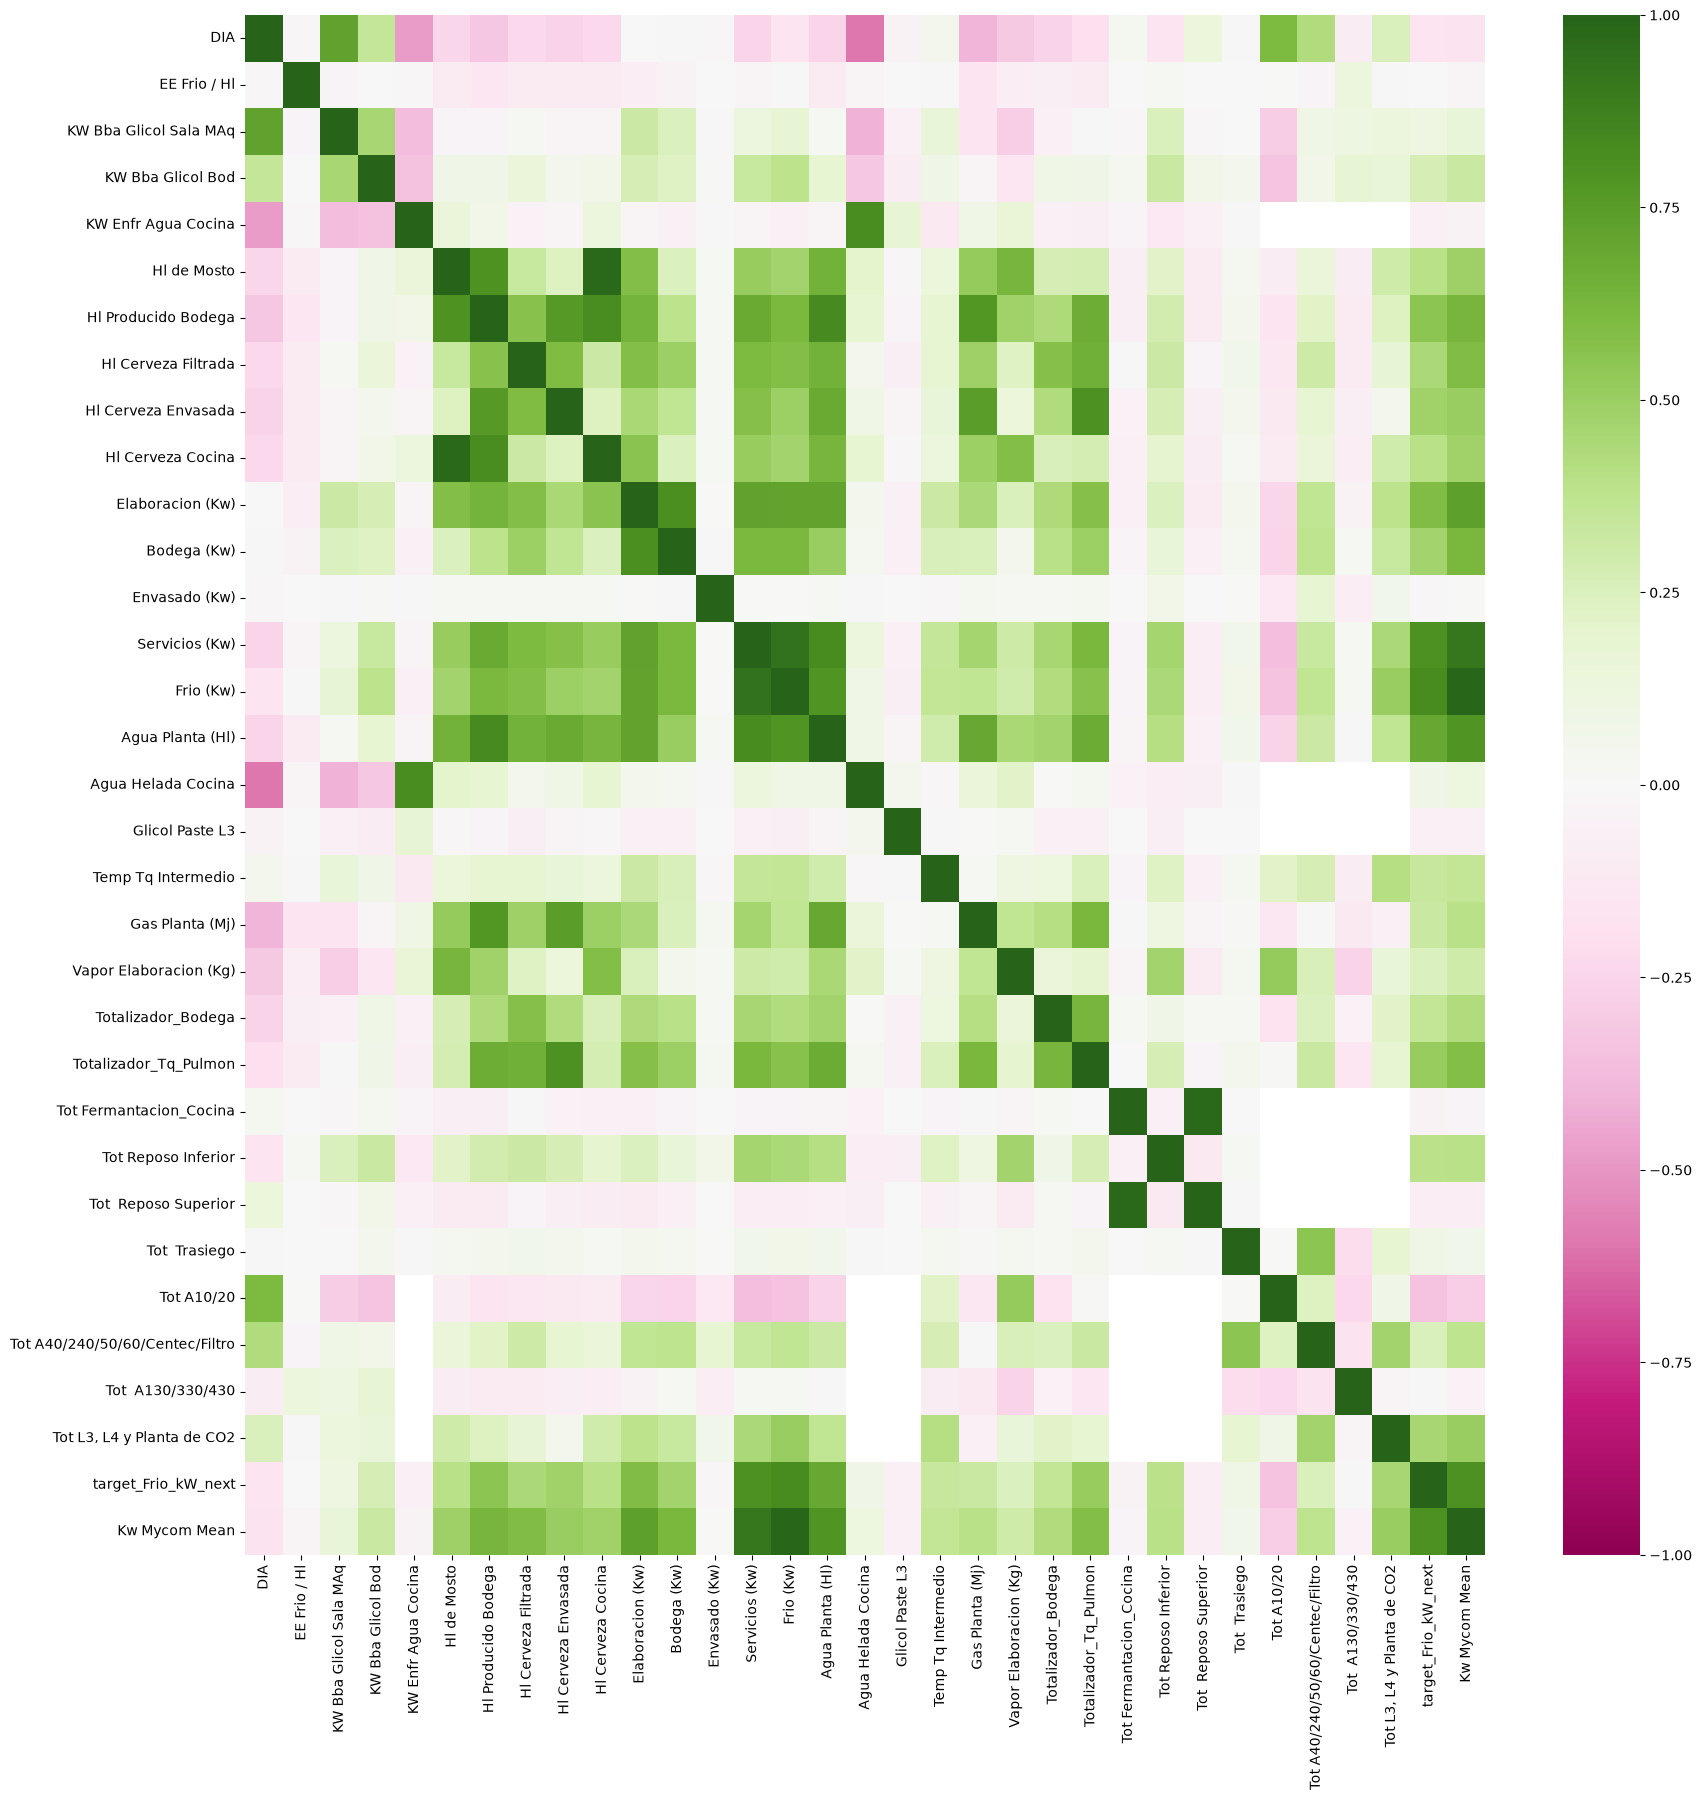

In [150]:
mtx_correlacion = df_sin_frio_outliers.corr() 
plt.figure(figsize=(20,20))
sns.heatmap(data=mtx_correlacion, cmap="PiYG",vmin=-1, vmax=1)


In [151]:
display(mtx_correlacion["target_Frio_kW_next"])

DIA                               -0.171660
EE Frio / Hl                      -0.005870
KW Bba Glicol Sala MAq             0.107474
KW Bba Glicol Bod                  0.270240
KW Enfr Agua Cocina               -0.069414
Hl de Mosto                        0.394797
Hl Producido Bodega                0.552162
Hl Cerveza Filtrada                0.443805
Hl Cerveza Envasada                0.479147
Hl Cerveza Cocina                  0.396287
Elaboracion (Kw)                   0.587546
Bodega (Kw)                        0.471079
Envasado (Kw)                     -0.022413
Servicios (Kw)                     0.800732
Frio (Kw)                          0.821090
Agua Planta (Hl)                   0.695154
Agua Helada Cocina                 0.084805
Glicol Paste L3                   -0.067849
Temp Tq Intermedio                 0.338225
Gas Planta (Mj)                    0.324737
Vapor Elaboracion (Kg)             0.246856
Totalizador_Bodega                 0.351774
Totalizador_Tq_Pulmon           

In [152]:
columns_corr_target =mtx_correlacion["target_Frio_kW_next"].abs().sort_values(ascending=False).index[1:16]
columns_corr_target

Index(['Frio (Kw)', 'Servicios (Kw)', 'Kw Mycom Mean', 'Agua Planta (Hl)',
       'Elaboracion (Kw)', 'Hl Producido Bodega', 'Totalizador_Tq_Pulmon',
       'Hl Cerveza Envasada', 'Bodega (Kw)', 'Tot L3, L4 y Planta de CO2',
       'Hl Cerveza Filtrada', 'Hl Cerveza Cocina', 'Hl de Mosto',
       'Tot Reposo Inferior', 'Totalizador_Bodega'],
      dtype='str')

In [153]:
mtx_correlacion_spearman = df_sin_frio_outliers.corr(method="spearman") 
columns_corr_target_spearman = mtx_correlacion_spearman["target_Frio_kW_next"].abs().sort_values(ascending=False).index[1:16]
columns_corr_target_spearman

Index(['Frio (Kw)', 'Kw Mycom Mean', 'Servicios (Kw)', 'Agua Planta (Hl)',
       'Tot L3, L4 y Planta de CO2', 'Elaboracion (Kw)', 'Hl Producido Bodega',
       'Bodega (Kw)', 'Temp Tq Intermedio', 'Envasado (Kw)',
       'Totalizador_Tq_Pulmon', 'Hl Cerveza Envasada', 'Hl Cerveza Filtrada',
       'Hl Cerveza Cocina', 'Hl de Mosto'],
      dtype='str')

<Axes: >

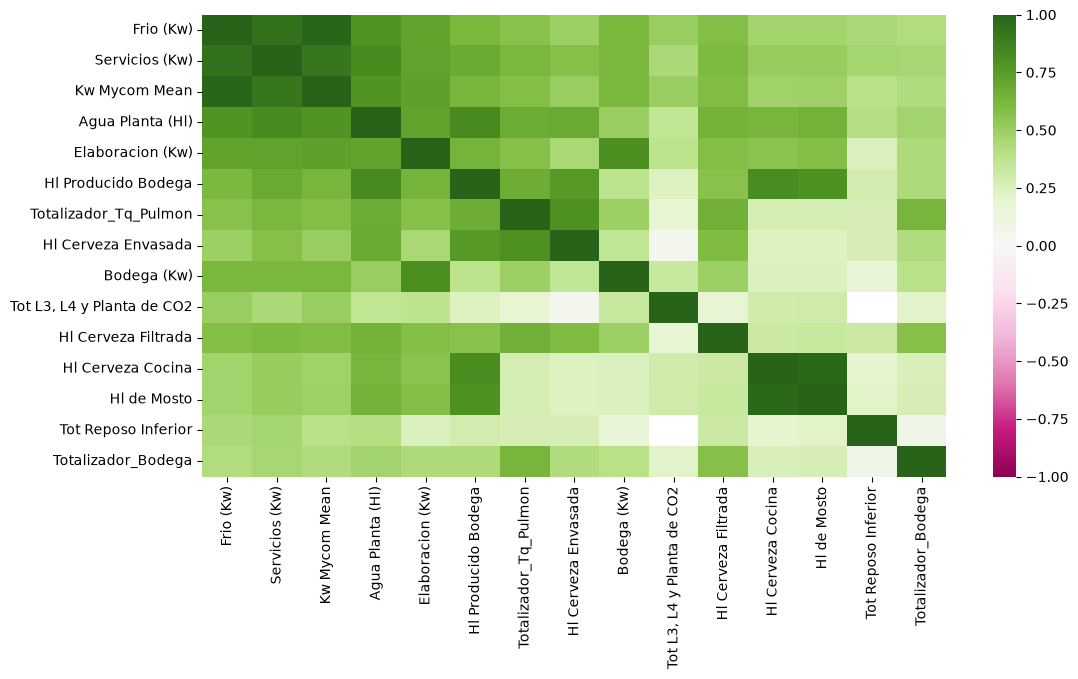

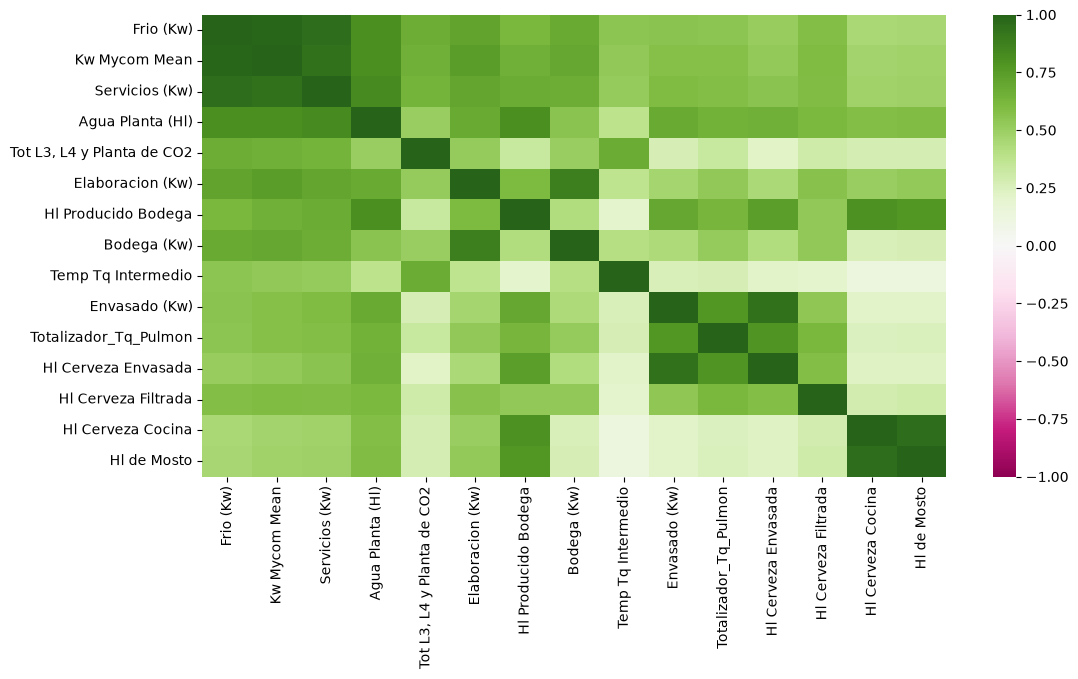

In [154]:
mtx_15_corr_pearson = df_sin_frio_outliers[columns_corr_target].corr()
plt.figure(figsize=(12,6))
sns.heatmap(data=mtx_15_corr_pearson, cmap="PiYG",vmin=-1, vmax=1)

mtx_15_corr_spearman = df_sin_frio_outliers[columns_corr_target_spearman].corr(method="spearman")
plt.figure(figsize=(12,6))
sns.heatmap(data=mtx_15_corr_spearman, cmap="PiYG",vmin=-1, vmax=1)


### Visualizaciones Requeridas

<Axes: xlabel='DIA', ylabel='target_Frio_kW_next'>

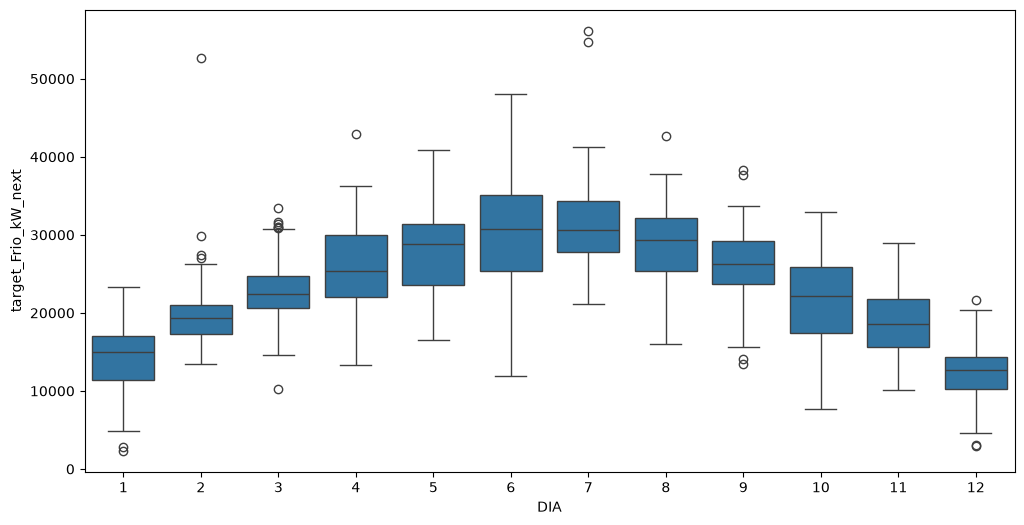

In [155]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_sin_frio_outliers, x=df_sin_frio_outliers["DIA"].dt.month, y= "target_Frio_kW_next")

Se observa que en los meses en donde es verano (Mexico) hay mayor consumo de Frío 

<Axes: xlabel='target_Frio_kW_next', ylabel='Count'>

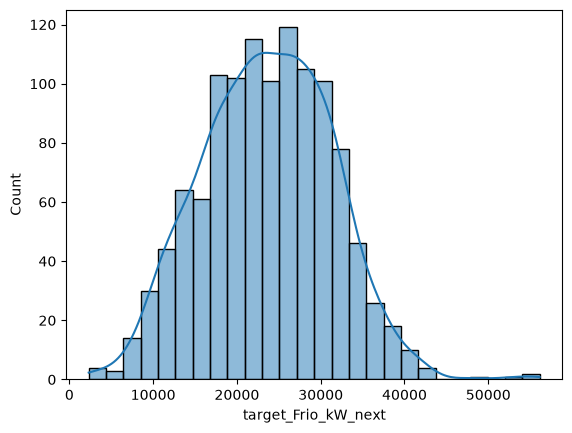

In [156]:
sns.histplot(data=df_sin_frio_outliers, x="target_Frio_kW_next", kde=True)

((array([-3.23816347, -2.97602803, -2.82994209, ...,  2.82994209,
          2.97602803,  3.23816347], shape=(1152,)),
  array([ 2310.,  2770.,  2910., ..., 52655., 54681., 56128.], shape=(1152,))),
 (np.float64(7690.846380219614),
  np.float64(23645.083333333332),
  np.float64(0.9971942020612925)))

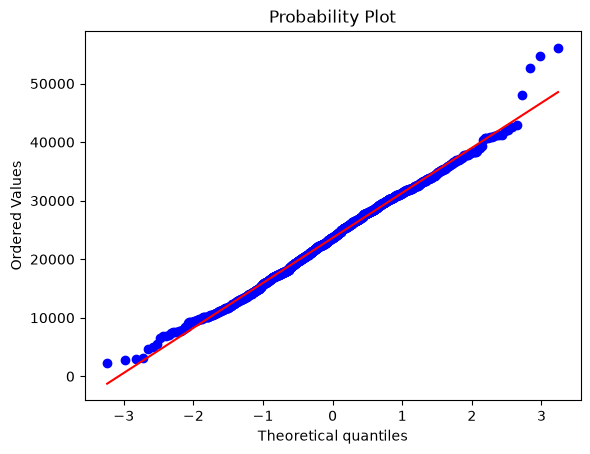

In [157]:
stats.probplot(df_sin_frio_outliers["target_Frio_kW_next"], plot=plt)

Se observa que la target tiene una distribución aproximadamente normal

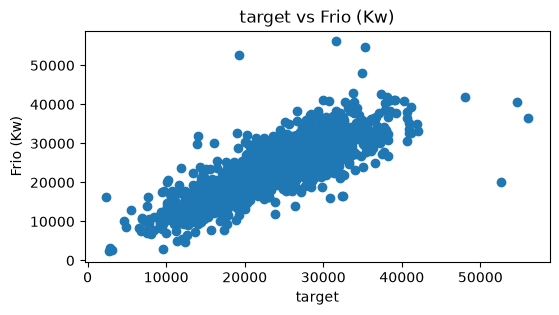

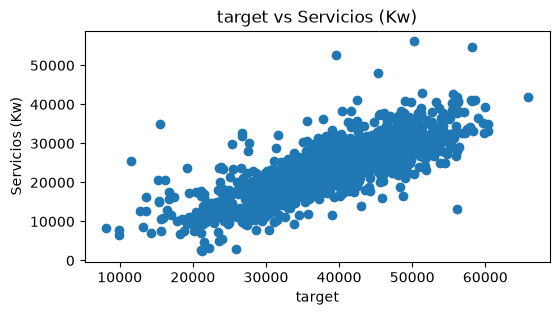

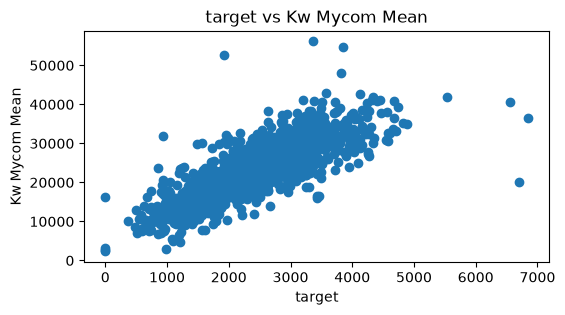

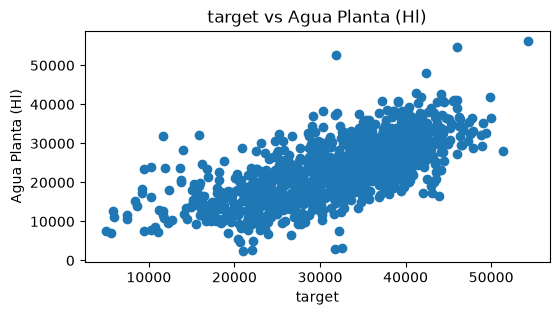

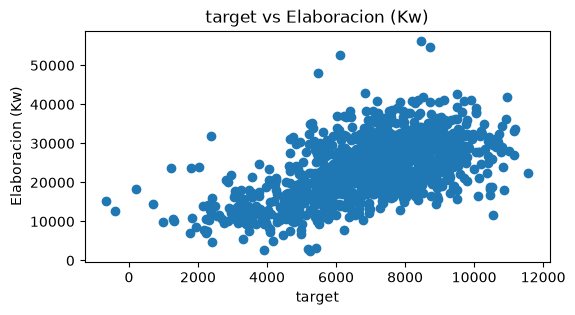

In [158]:
#columns_corr_target_spearman
#columns_corr_target

for c in columns_corr_target[:5]:
    plt.figure(figsize=(6,3))
    plt.scatter(x=df_sin_frio_outliers[c], y=df_sin_frio_outliers["target_Frio_kW_next"])
    plt.title(f"target vs {c}")
    plt.ylabel(c)
    plt.xlabel("target")

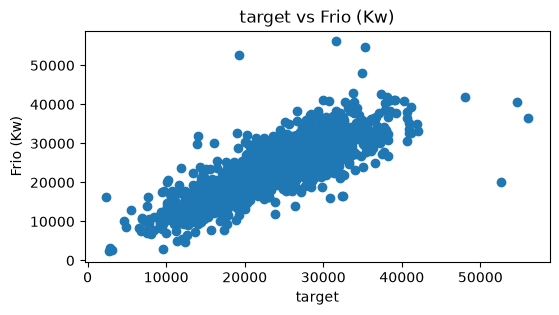

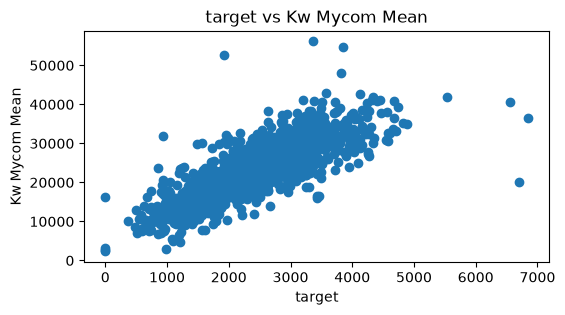

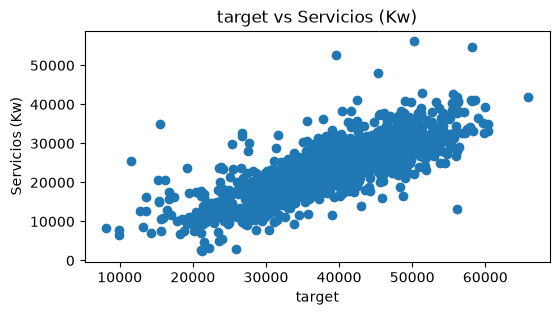

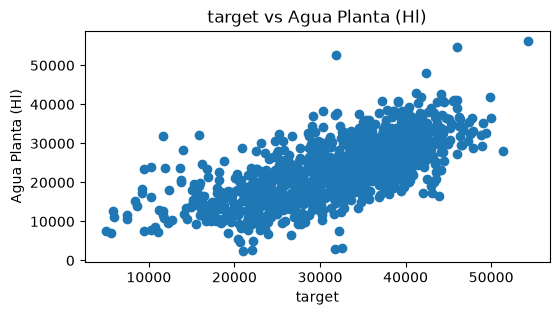

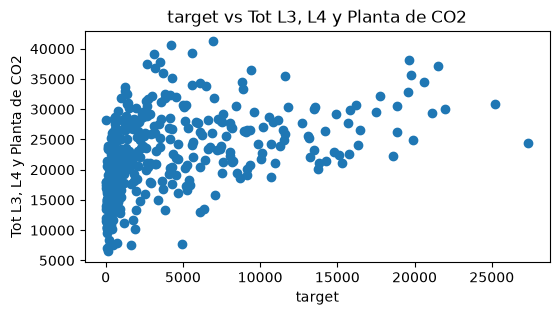

In [159]:

for c in columns_corr_target_spearman[:5]:
    plt.figure(figsize=(6,3))
    plt.scatter(x=df_sin_frio_outliers[c], y=df_sin_frio_outliers["target_Frio_kW_next"])
    plt.title(f"target vs {c}")
    plt.ylabel(c)
    plt.xlabel("target")

In [160]:
df_sin_frio_outliers.columns

Index(['DIA', 'EE Frio / Hl', 'KW Bba Glicol Sala MAq', 'KW Bba Glicol Bod',
       'KW Enfr Agua Cocina', 'Hl de Mosto', 'Hl Producido Bodega',
       'Hl Cerveza Filtrada', 'Hl Cerveza Envasada', 'Hl Cerveza Cocina',
       'Elaboracion (Kw)', 'Bodega (Kw)', 'Envasado (Kw)', 'Servicios (Kw)',
       'Frio (Kw)', 'Agua Planta (Hl)', 'Agua Helada Cocina',
       'Glicol Paste L3', 'Temp Tq Intermedio', 'Gas Planta (Mj)',
       'Vapor Elaboracion (Kg)', 'Totalizador_Bodega', 'Totalizador_Tq_Pulmon',
       'Tot Fermantacion_Cocina', 'Tot Reposo Inferior',
       'Tot  Reposo Superior', 'Tot  Trasiego', 'Tot A10/20',
       'Tot A40/240/50/60/Centec/Filtro', 'Tot  A130/330/430',
       'Tot L3, L4 y Planta de CO2', 'target_Frio_kW_next', 'Kw Mycom Mean'],
      dtype='str')

# COMPLETO

## EDA Univariado

In [161]:
df_completo = df_completo.replace(' ', np.nan)
columnas_numericas = ~df_completo.columns.isin(["DIA", "HORA"])
df_completo.loc[:, columnas_numericas] = (
    df_completo.loc[:, columnas_numericas]
    .apply(pd.to_numeric, errors="coerce")
)

### Valores nulos: 

In [162]:
print("Porcentaje de valores nulos por columna: (el resto no tiene valores nulos)")
print(df_completo[df_completo.columns[df_completo.isna().any()]].isna().sum().sort_values(ascending=False)/df_completo.shape[0]*100)

Porcentaje de valores nulos por columna: (el resto no tiene valores nulos)
EE Linea 5 / Hl             100.000000
.9                          100.000000
.8                          100.000000
.15                         100.000000
.14                         100.000000
                               ...    
Totalizador Bba P2            0.086059
Totalizador Bba P51           0.086059
Totalizador Bba P4            0.086059
Totalizador Bba Envasado      0.086059
Totalizador Bba P1            0.086059
Length: 172, dtype: float64


In [163]:
print(df_completo.columns[df_completo.columns.str.contains("Trafo")])

Index(['KW Trafo 4', 'KW Trafo 5', 'KW Trafo 8', 'KW Trafo 11', 'KW Trafo 12',
       'KW Trafo 9', 'KW Trafo 10'],
      dtype='str')


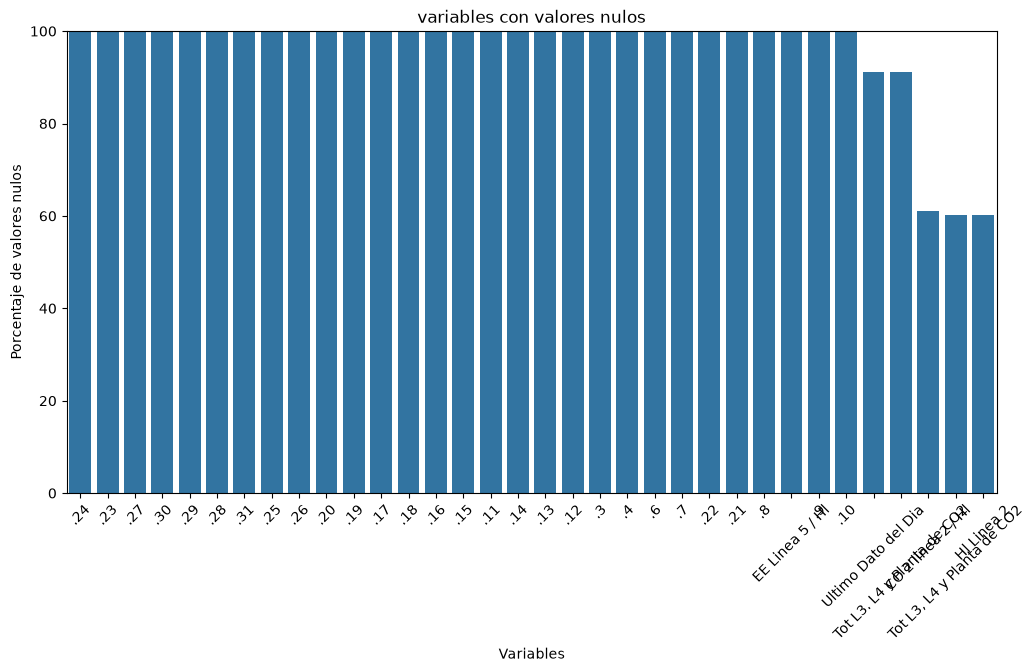

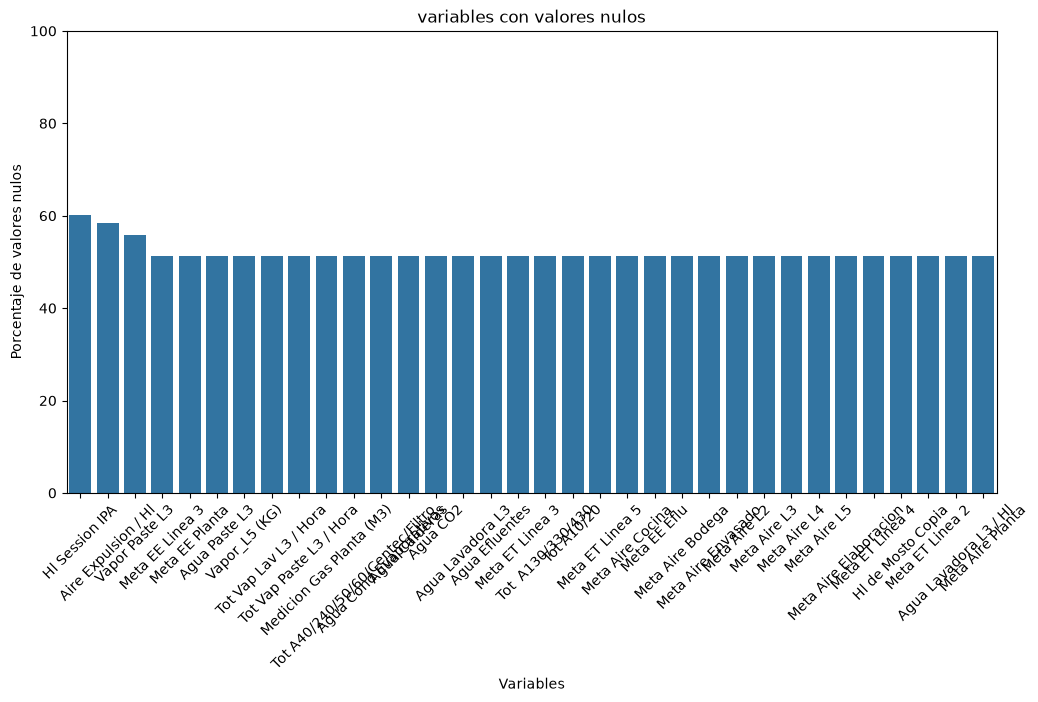

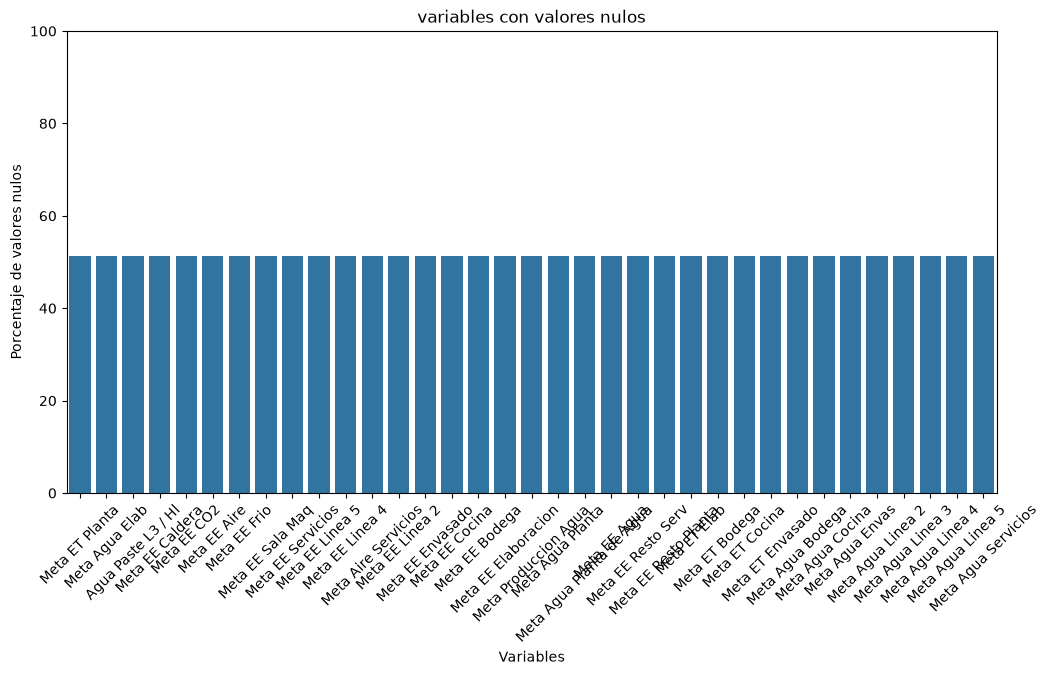

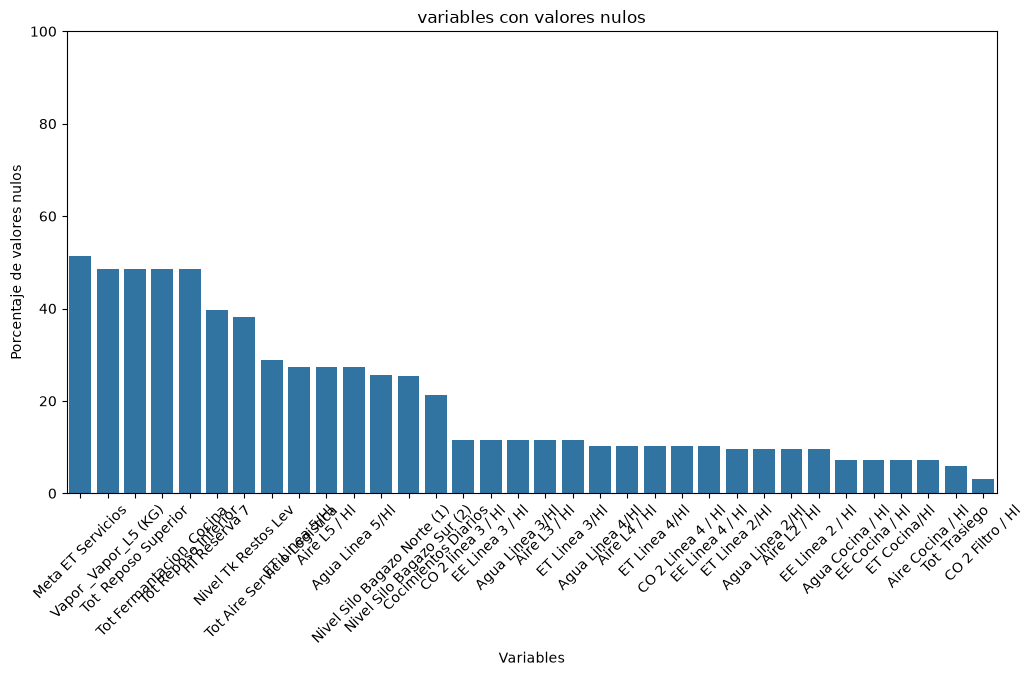

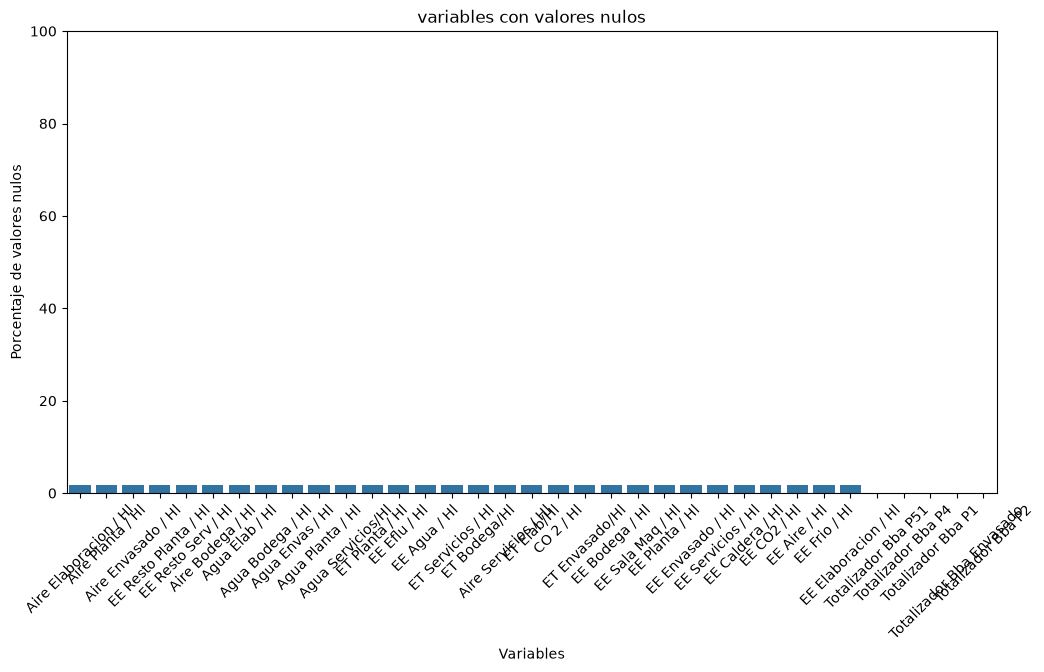

In [164]:
nulos = df_completo.isna().sum().sort_values(ascending=False)/df_completo.shape[0]*100
nulos = nulos[nulos>0]
k = 5
for i in range(k):
    plt.figure(figsize=(12,6))
    nulos_parte = nulos[i*nulos.shape[0]//k:(i+1)*nulos.shape[0]//k]
    sns.barplot(x=nulos_parte.index,y=nulos_parte.values)
    plt.title("variables con valores nulos")
    plt.ylabel("Porcentaje de valores nulos")
    plt.xlabel("Variables")
    plt.xticks(rotation=45)
    plt.ylim(0,100)
    plt.show()


In [165]:
df_completo = df_completo.drop(columns=nulos[nulos>50].index)

### Valores con cero

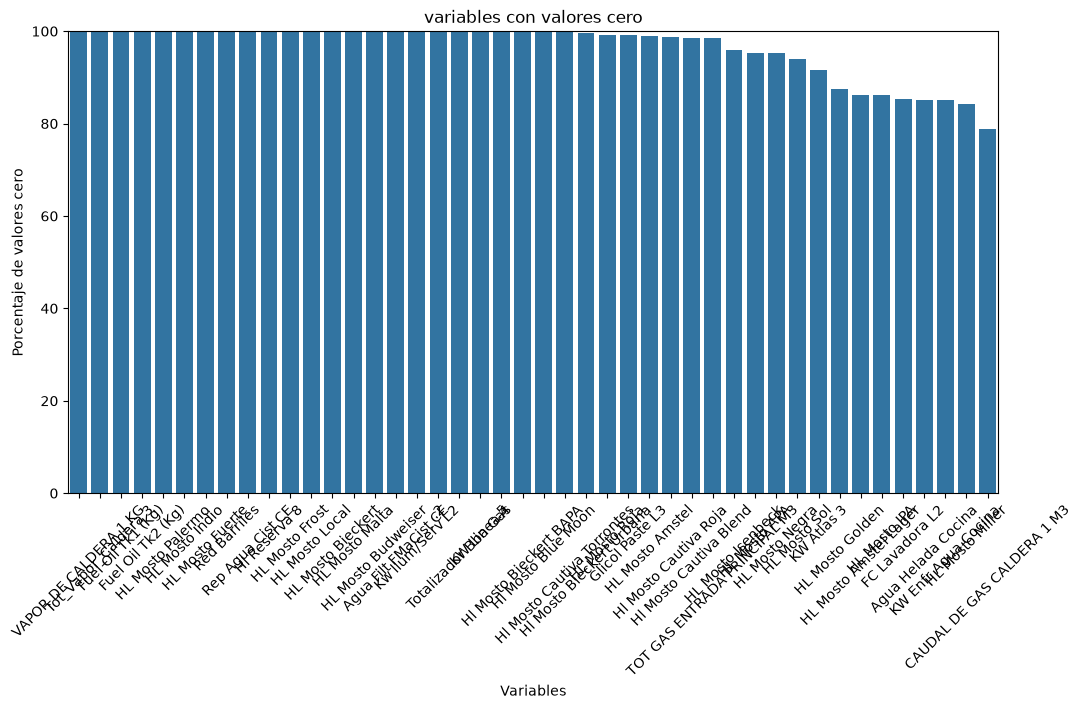

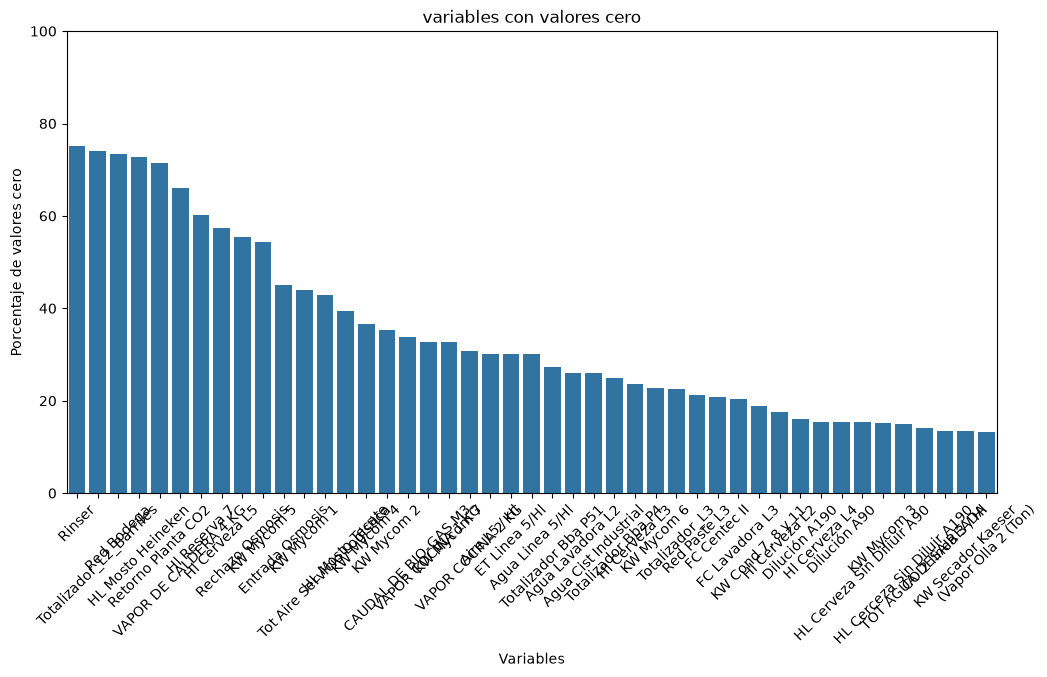

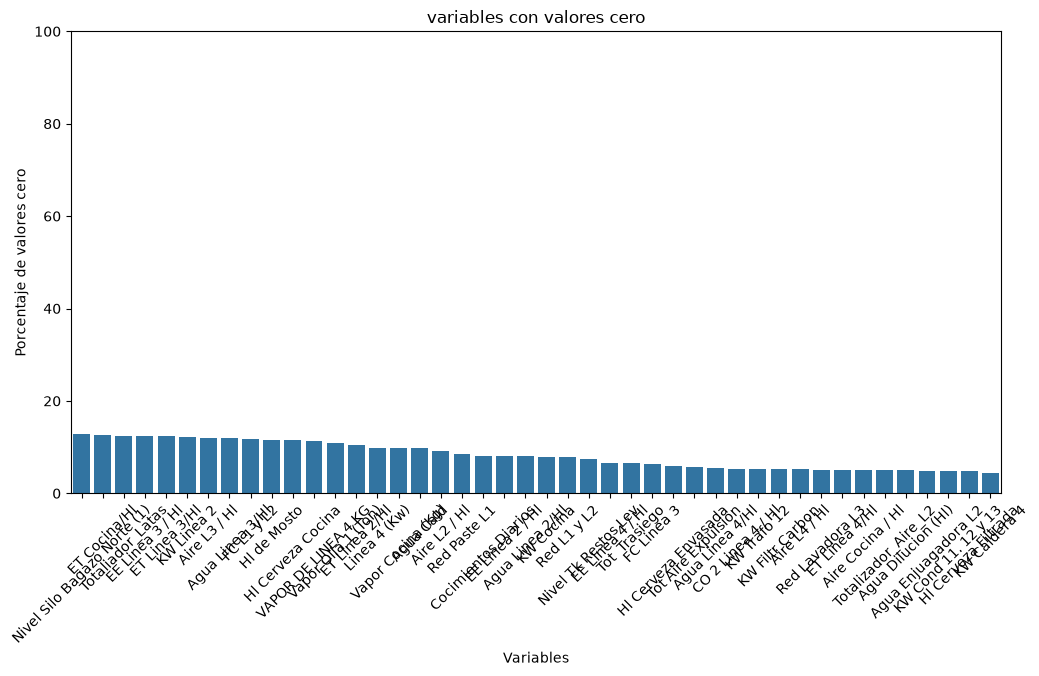

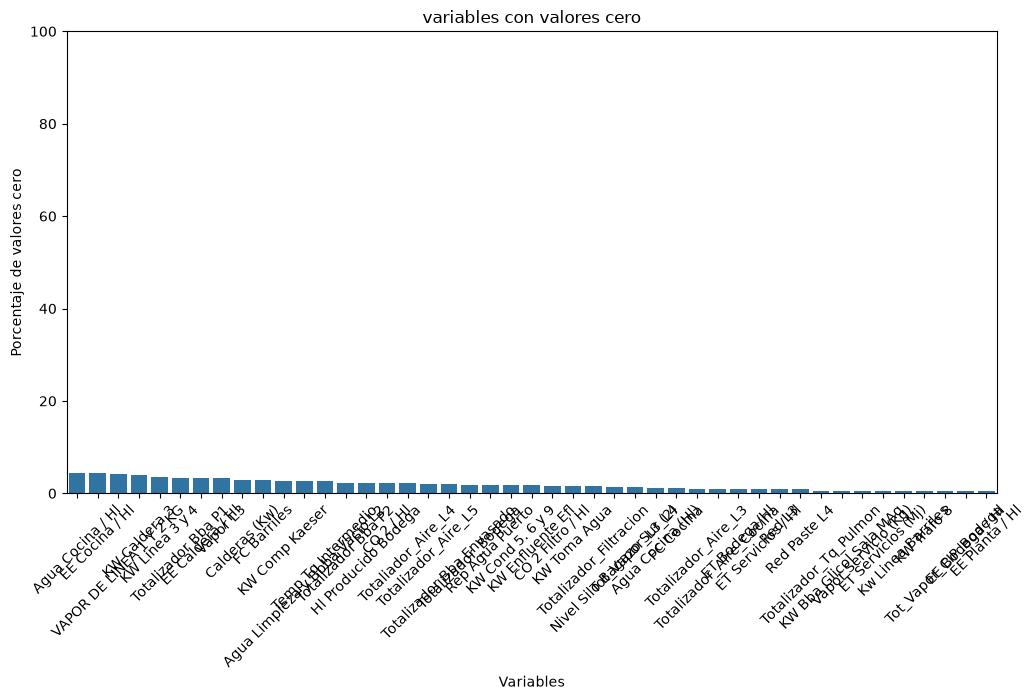

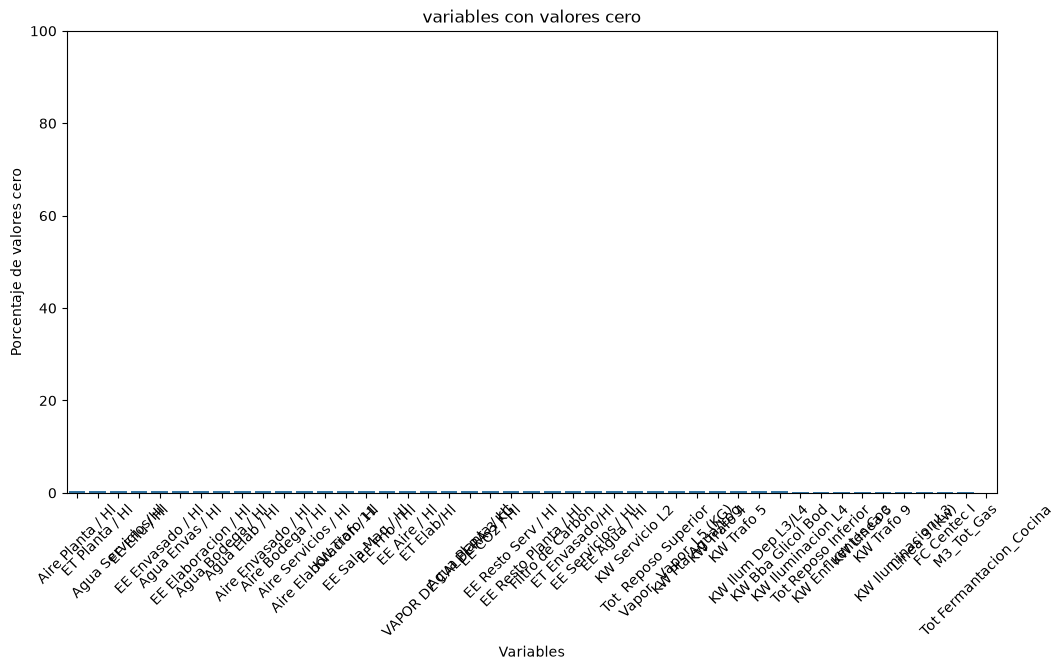

In [166]:
ceros = (df_completo==0).sum().sort_values(ascending=False)/df_completo.shape[0]*100
ceros = ceros[ceros>0]
k = 5
for i in range(k):
    plt.figure(figsize=(12,6))
    ceros_parte = ceros[i*ceros.shape[0]//k:(i+1)*ceros.shape[0]//k]
    sns.barplot(x=ceros_parte.index,y=ceros_parte.values)
    plt.title("variables con valores cero")
    plt.ylabel("Porcentaje de valores cero")
    plt.xlabel("Variables")
    plt.xticks(rotation=45)
    plt.ylim(0,100)
    plt.show()


In [167]:
df_completo = df_completo.drop(columns=ceros[ceros>50].index)

Porcentaje de valores cero en Kw Mycom Mean: 0.43%
Las filas donde se producen outliers extremos:


,DIA,Unnamed: 0,HORA,EE Planta / Hl,EE Elaboracion / Hl,EE Bodega / Hl,EE Cocina / Hl,EE Envasado / Hl,EE Linea 2 / Hl,EE Linea 3 / Hl,EE Linea 4 / Hl,EE Servicios / Hl,EE Sala Maq / Hl,EE Frio / Hl,EE Aire / Hl,EE CO2 / Hl,EE Caldera / Hl,EE Eflu / Hl,EE Agua / Hl,EE Resto Serv / Hl,EE Resto Planta / Hl,Agua Planta / Hl,Agua Elab / Hl,Agua Bodega / Hl,Agua Cocina / Hl,Agua Envas / Hl,Agua Linea 2/Hl,Agua Linea 3/Hl,Agua Linea 4/Hl,Agua Linea 5/Hl,Agua Servicios/Hl,Agua Planta de Agua/Hl,Produccion Agua / Hl,ET Planta / Hl,ET Elab/Hl,ET Bodega/Hl,ET Cocina/Hl,ET Envasado/Hl,ET Linea 2/Hl,ET Linea 3/Hl,ET Linea 4/Hl,ET Linea 5/Hl,ET Servicios / Hl,Aire Planta / Hl,Aire Elaboracion / Hl,Aire Cocina / Hl,Aire Bodega / Hl,Aire Envasado / Hl,Aire L2 / Hl,Aire L3 / Hl,Aire L4 / Hl,Aire L5 / Hl,Aire Servicios / Hl,CO 2 / Hl,CO 2 Filtro / Hl,CO 2 linea 3 / Hl,CO 2 Linea 4 / Hl,Hl de Mosto,Hl Cerveza Cocina,Hl Producido Bodega,Hl Cerveza Filtrada,Hl Cerveza Envasada,Hl Cerveza L2,Hl Cerveza L3,Hl Cerveza L4,Cocimientos Diarios,HL Mosto Tecate,HL Cerveza Sin Diliuir A90,HL Cerceza Sin Diluir A190,Nivel Silo Bagazo Norte (1),Nivel Silo Bagazo Sur (2),Nivel Tk Restos Lev,Planta (Kw),Elaboracion (Kw),Bodega (Kw),Cocina (Kw),Envasado (Kw),Linea 2 (Kw),Linea 3 (Kw),Linea 4 (Kw),Servicios (Kw),Sala Maq (Kw),Aire (Kw),Calderas (Kw),Efluentes (Kw),Frio (Kw),Pta Agua / Eflu (Kw),Prod Agua (Kw),Resto Serv (Kw),Restos Planta (Kw),KW Gral Planta,KW Trafo 4,KW Trafo 5,KW Trafo 8,KW Trafo 11,KW Trafo 12,KW Linea 2,KW Mycom 1,KW Mycom 2,KW Mycom 3,KW Mycom 4,KW Mycom 6,KW Mycom 7,KW Trafo 9,KW Trafo 10,KW Cocina,Kw Molino,KW Linea 3 y 4,KW Linea 3,KW Servicio L2,KW Planta de Agua,Kw Casona,KW Laboratorio,Kw Admininistracion,KW Pta Agua/Log,KW Bba Glicol Sala MAq,KW Comp Kaeser,KW Iluminacion L3,KW Iluminacion L4,KW Ilum Dep L3/L4,KW Cond 5. 6 y 9,KW Cond 7. 8 y 11,KW Cond 11. 12 y 13,KW Bba Glicol Bod,KW CO2,KW Secador Kaeser,KW Caldera 3,KW Caldera 4,KW Filtr Carbon,KW Toma Agua,KW Enfluentes Coc,KW Enfluente Efl,KW Enfluentes Hidr,KW Obrador Contratistas,Kw Compresores Aire,Kw Linea Barriles,Agua Planta (Hl),Agua Elaboracion (Hl),Agua Bodega (Hl),Agua Cocina (Hl),Agua Dilucion (Hl),Agua Envasado (Hl),Agua Servicios (Hl),Planta de agua (Hl),Produccion (Hl),Red L1 y L2,FC L1 y L2,Red L3,FC Lavadora L3,Red Paste L4,FC Barriles,Red Paste L1,FC Linea 3,FC CIP Bodega,FC Centec I,FC Cocina,FC Centec II,Agua Cond REC,Agua Red Servicios,Agua Cald,Agua Cist Industrial,Rep Agua Puerto,Entrada Osmosis,Red Administracion,Filtro de Carbon,Assa,Red Paste L3,Red Lavadora L3,Dilución A90,Dilución A190,Red Bodega Interno,Agua Planta CO2,Agua Limpieza y Bbba Vacio L2,Agua Enjuagadora L2,Agua Lavadora L2,Temp Tq Intermedio,Conversion Kg/Mj,Gas Planta (Mj),Vapor Elaboracion (Kg),Vapor Cocina (Kg),Vapor Envasado (Kg),Vapor Servicio (Kg),ET Elaboracion (Mj),ET Envasado (Mj),ET Servicios (Mj),Tot_Vapor_L3_L4,VAPOR DE LINEA 1 Y 2 KG,VAPOR DE LINEA 4 KG,Tot_Vapor_CIP_Bodega,Vapor L3,M3_Tot_Gas,CAUDAL DE BIO-GAS M3,VAPOR DE CALDERA 3 KG,VAPOR COCINA 1 KG,VAPOR COCINA 2 KG,TOT AGUA DESAIREADA,Vapor Olla 1 (Ton),(Vapor Olla 2 (Ton),Aire Producido (M3),Aire Planta (M3),Aire Elaboracion (m3),Aire Envasado (M3),Aire Servicios (M3),Tot Aire Expulsion,Totalizador_Aire_Bodega,Totalizador_Aire_Cocina,Totalizador_Aire_L2,Totalizador_Aire_L3,Totaliador_Aire_L4,Totalizador_Aire_L5,Totalizador Sistema Kaeser,Tot Aire Servicio Logistica,Totalizador_L3,Totaliador_Latas,Totalizador_Bodega,Totalizador_Tq_Pulmon,Totalizador_Filtracion,Totalizador Bba P1,Totalizador Bba P2,Totalizador Bba P4,Totalizador Bba Envasado,Totalizador Bba P51,Tot Trasiego,.1,Vapor _Vapor_L5 (KG),Tot Fermantacion_Cocina,Tot Reposo Inferior,Tot Reposo Superior,target_Frio_kW_next,Kw Mycom Mean
297,2021-04-30,7447,23:59:00,8.851658,1.032235,0.949554,0.230199,1.247372e+00,0.000000,97.500000,1.497630,6.135715,712.444075,712.156289,0.690457,0.345548,0.112968,0.134948,0.115396,-707.419891,4.363362e-01,4.081850,2.018466,0.855

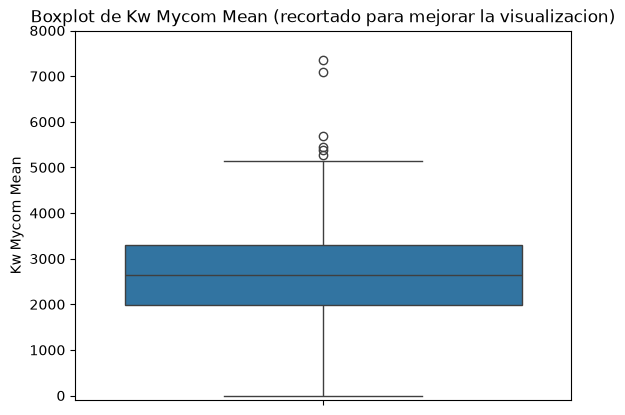

In [168]:
#Muchos de los valores de Mycom son 0, por lo que se calcula la media de las columnas de Mycom.
#La presencia de outliers imposibilita la correcta visualización del boxplot
mycoms = df_completo.columns[df_completo.columns.str.contains("Mycom")]
df_completo["Kw Mycom Mean"] = df_completo.loc[:, mycoms].mean(axis=1, skipna=True) 
sns.boxplot(df_completo, y="Kw Mycom Mean")
plt.ylim(-100,8000) 
plt.title("Boxplot de Kw Mycom Mean (recortado para mejorar la visualizacion)")
cant_ceros = (df_completo["Kw Mycom Mean"]==0).sum()/df_completo.shape[0]*100
print(f"Porcentaje de valores cero en Kw Mycom Mean: {cant_ceros:.2f}%")
print("Las filas donde se producen outliers extremos:")
display(df_completo[df_completo["Kw Mycom Mean"] > 0.3e6])

In [169]:
# dropeo de las mycoms, nos quedamos con la mean
df_completo = df_completo.drop(columns=mycoms, errors= "ignore")
df_completo.columns

Index(['DIA', 'Unnamed: 0', 'HORA', 'EE Planta / Hl', 'EE Elaboracion / Hl',
       'EE Bodega / Hl', 'EE Cocina / Hl', 'EE Envasado / Hl',
       'EE Linea 2 / Hl', 'EE Linea 3 / Hl',
       ...
       'Totalizador Bba Envasado', 'Totalizador Bba P51', 'Tot  Trasiego',
       '.1', 'Vapor _Vapor_L5 (KG)', 'Tot Fermantacion_Cocina',
       'Tot Reposo Inferior', 'Tot  Reposo Superior', 'target_Frio_kW_next',
       'Kw Mycom Mean'],
      dtype='str', length=224)

In [170]:
trafos = df_completo.columns[df_completo.columns.str.contains("Trafo")]
df_completo["Kw Trafo Mean"] = df_completo.loc[:, trafos].mean(axis=1, skipna=True) 


Porcentaje de valores cero en Kw Trafos Mean: 0.00%
Las filas donde se producen outliers extremos:


,DIA,Unnamed: 0,HORA,EE Planta / Hl,EE Elaboracion / Hl,EE Bodega / Hl,EE Cocina / Hl,EE Envasado / Hl,EE Linea 2 / Hl,EE Linea 3 / Hl,EE Linea 4 / Hl,EE Servicios / Hl,EE Sala Maq / Hl,EE Frio / Hl,EE Aire / Hl,EE CO2 / Hl,EE Caldera / Hl,EE Eflu / Hl,EE Agua / Hl,EE Resto Serv / Hl,EE Resto Planta / Hl,Agua Planta / Hl,Agua Elab / Hl,Agua Bodega / Hl,Agua Cocina / Hl,Agua Envas / Hl,Agua Linea 2/Hl,Agua Linea 3/Hl,Agua Linea 4/Hl,Agua Linea 5/Hl,Agua Servicios/Hl,Agua Planta de Agua/Hl,Produccion Agua / Hl,ET Planta / Hl,ET Elab/Hl,ET Bodega/Hl,ET Cocina/Hl,ET Envasado/Hl,ET Linea 2/Hl,ET Linea 3/Hl,ET Linea 4/Hl,ET Linea 5/Hl,ET Servicios / Hl,Aire Planta / Hl,Aire Elaboracion / Hl,Aire Cocina / Hl,Aire Bodega / Hl,Aire Envasado / Hl,Aire L2 / Hl,Aire L3 / Hl,Aire L4 / Hl,Aire L5 / Hl,Aire Servicios / Hl,CO 2 / Hl,CO 2 Filtro / Hl,CO 2 linea 3 / Hl,CO 2 Linea 4 / Hl,Hl de Mosto,Hl Cerveza Cocina,Hl Producido Bodega,Hl Cerveza Filtrada,Hl Cerveza Envasada,Hl Cerveza L2,Hl Cerveza L3,Hl Cerveza L4,Cocimientos Diarios,HL Mosto Tecate,HL Cerveza Sin Diliuir A90,HL Cerceza Sin Diluir A190,Nivel Silo Bagazo Norte (1),Nivel Silo Bagazo Sur (2),Nivel Tk Restos Lev,Planta (Kw),Elaboracion (Kw),Bodega (Kw),Cocina (Kw),Envasado (Kw),Linea 2 (Kw),Linea 3 (Kw),Linea 4 (Kw),Servicios (Kw),Sala Maq (Kw),Aire (Kw),Calderas (Kw),Efluentes (Kw),Frio (Kw),Pta Agua / Eflu (Kw),Prod Agua (Kw),Resto Serv (Kw),Restos Planta (Kw),KW Gral Planta,KW Trafo 4,KW Trafo 5,KW Trafo 8,KW Trafo 11,KW Trafo 12,KW Linea 2,KW Trafo 9,KW Trafo 10,KW Cocina,Kw Molino,KW Linea 3 y 4,KW Linea 3,KW Servicio L2,KW Planta de Agua,Kw Casona,KW Laboratorio,Kw Admininistracion,KW Pta Agua/Log,KW Bba Glicol Sala MAq,KW Comp Kaeser,KW Iluminacion L3,KW Iluminacion L4,KW Ilum Dep L3/L4,KW Cond 5. 6 y 9,KW Cond 7. 8 y 11,KW Cond 11. 12 y 13,KW Bba Glicol Bod,KW CO2,KW Secador Kaeser,KW Caldera 3,KW Caldera 4,KW Filtr Carbon,KW Toma Agua,KW Enfluentes Coc,KW Enfluente Efl,KW Enfluentes Hidr,KW Obrador Contratistas,Kw Compresores Aire,Kw Linea Barriles,Agua Planta (Hl),Agua Elaboracion (Hl),Agua Bodega (Hl),Agua Cocina (Hl),Agua Dilucion (Hl),Agua Envasado (Hl),Agua Servicios (Hl),Planta de agua (Hl),Produccion (Hl),Red L1 y L2,FC L1 y L2,Red L3,FC Lavadora L3,Red Paste L4,FC Barriles,Red Paste L1,FC Linea 3,FC CIP Bodega,FC Centec I,FC Cocina,FC Centec II,Agua Cond REC,Agua Red Servicios,Agua Cald,Agua Cist Industrial,Rep Agua Puerto,Entrada Osmosis,Red Administracion,Filtro de Carbon,Assa,Red Paste L3,Red Lavadora L3,Dilución A90,Dilución A190,Red Bodega Interno,Agua Planta CO2,Agua Limpieza y Bbba Vacio L2,Agua Enjuagadora L2,Agua Lavadora L2,Temp Tq Intermedio,Conversion Kg/Mj,Gas Planta (Mj),Vapor Elaboracion (Kg),Vapor Cocina (Kg),Vapor Envasado (Kg),Vapor Servicio (Kg),ET Elaboracion (Mj),ET Envasado (Mj),ET Servicios (Mj),Tot_Vapor_L3_L4,VAPOR DE LINEA 1 Y 2 KG,VAPOR DE LINEA 4 KG,Tot_Vapor_CIP_Bodega,Vapor L3,M3_Tot_Gas,CAUDAL DE BIO-GAS M3,VAPOR DE CALDERA 3 KG,VAPOR COCINA 1 KG,VAPOR COCINA 2 KG,TOT AGUA DESAIREADA,Vapor Olla 1 (Ton),(Vapor Olla 2 (Ton),Aire Producido (M3),Aire Planta (M3),Aire Elaboracion (m3),Aire Envasado (M3),Aire Servicios (M3),Tot Aire Expulsion,Totalizador_Aire_Bodega,Totalizador_Aire_Cocina,Totalizador_Aire_L2,Totalizador_Aire_L3,Totaliador_Aire_L4,Totalizador_Aire_L5,Totalizador Sistema Kaeser,Tot Aire Servicio Logistica,Totalizador_L3,Totaliador_Latas,Totalizador_Bodega,Totalizador_Tq_Pulmon,Totalizador_Filtracion,Totalizador Bba P1,Totalizador Bba P2,Totalizador Bba P4,Totalizador Bba Envasado,Totalizador Bba P51,Tot Trasiego,.1,Vapor _Vapor_L5 (KG),Tot Fermantacion_Cocina,Tot Reposo Inferior,Tot Reposo Superior,target_Frio_kW_next,Kw Mycom Mean,Kw Trafo Mean


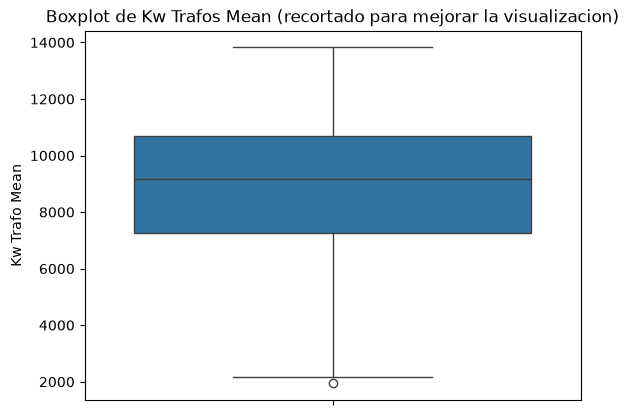

In [173]:

sns.boxplot(df_completo, y="Kw Trafo Mean")
plt.title("Boxplot de Kw Trafos Mean (recortado para mejorar la visualizacion)")
cant_ceros = (df_completo["Kw Trafo Mean"]==0).sum()/df_completo.shape[0]*100
print(f"Porcentaje de valores cero en Kw Trafos Mean: {cant_ceros:.2f}%")
print("Las filas donde se producen outliers extremos:")
display(df_completo[df_completo["Kw Trafo Mean"] > 0.3e6])

In [175]:
df_completo = df_completo.drop(columns=trafos, errors= "ignore")
df_completo.columns

Index(['DIA', 'Unnamed: 0', 'HORA', 'EE Planta / Hl', 'EE Elaboracion / Hl',
       'EE Bodega / Hl', 'EE Cocina / Hl', 'EE Envasado / Hl',
       'EE Linea 2 / Hl', 'EE Linea 3 / Hl',
       ...
       'Totalizador Bba P51', 'Tot  Trasiego', '.1', 'Vapor _Vapor_L5 (KG)',
       'Tot Fermantacion_Cocina', 'Tot Reposo Inferior',
       'Tot  Reposo Superior', 'target_Frio_kW_next', 'Kw Mycom Mean',
       'Kw Trafo Mean'],
      dtype='str', length=218)

### Valores atípicos: Detección con IQR modificado

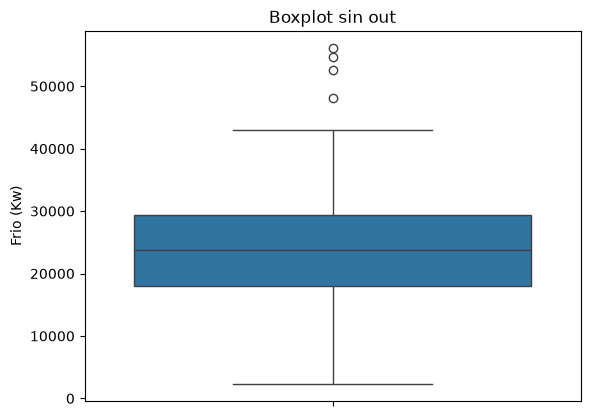

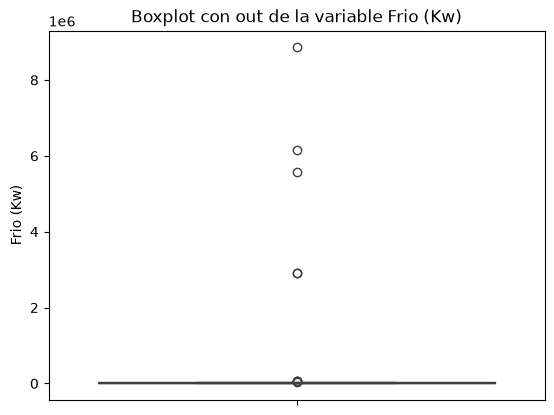

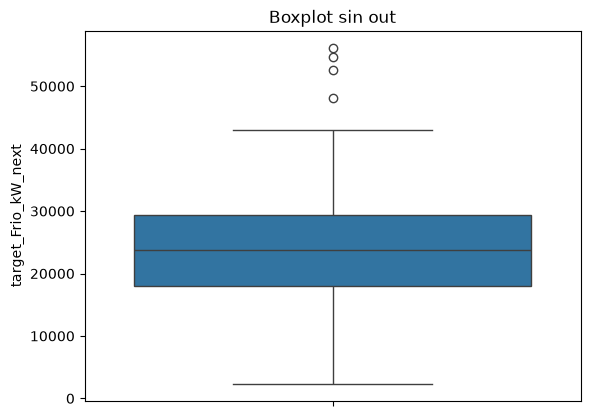

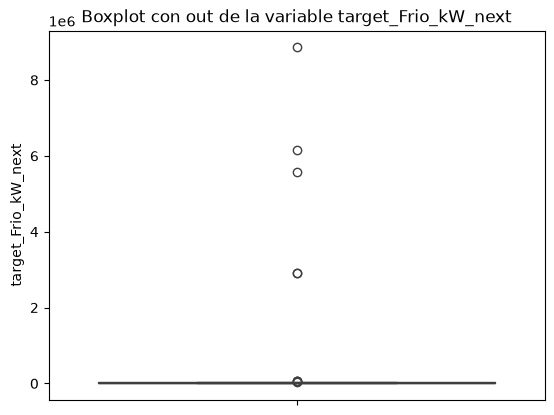

In [176]:
features_sin_dia = df_completo.columns[~df_completo.columns.isin(["DIA","HORA"])]
df_completo_sin_outliers = df_completo.copy()
for f in features_sin_dia: 
    Q1 = df_completo[f].quantile(0.25)
    Q3 = df_completo[f].quantile(0.75)
    P99 = df_completo[f].quantile(0.99)
    IQR = Q3 - Q1

    #no pusimos 1.5 ya que nos parece muy estricto
    outliers = df_completo[(df_completo[f] < - 3 * IQR + Q1 ) | (df_completo[f] >  3 * IQR + Q3 )].index
    df_completo_sin_outliers[f] = df_completo_sin_outliers[f].astype("float64")
    df_completo_sin_outliers.loc[outliers, f] = P99


    if f == 'Frio (Kw)' or f == 'target_Frio_kW_next':
        #df_completo_sin_outliers = df_completo_sin_outliers.drop(index = outliers)
        plt.figure()
        sns.boxplot(df_completo_sin_outliers, y=f) 
        plt.title("Boxplot sin out")
        plt.figure()
        sns.boxplot(df_completo, y=f)
        plt.title(f"Boxplot con out de la variable {f}")
        plt.show()

### Evolución temporal

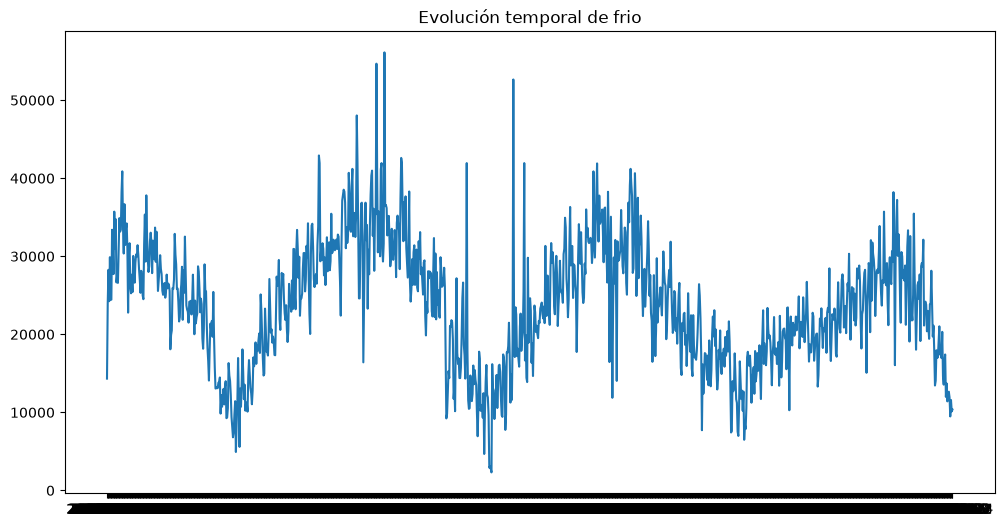

In [177]:
plt.figure(figsize=(12,6))
plt.plot(df_completo_sin_outliers["DIA"], df_completo_sin_outliers["Frio (Kw)"])
plt.title("Evolución temporal de frio")
plt.show()

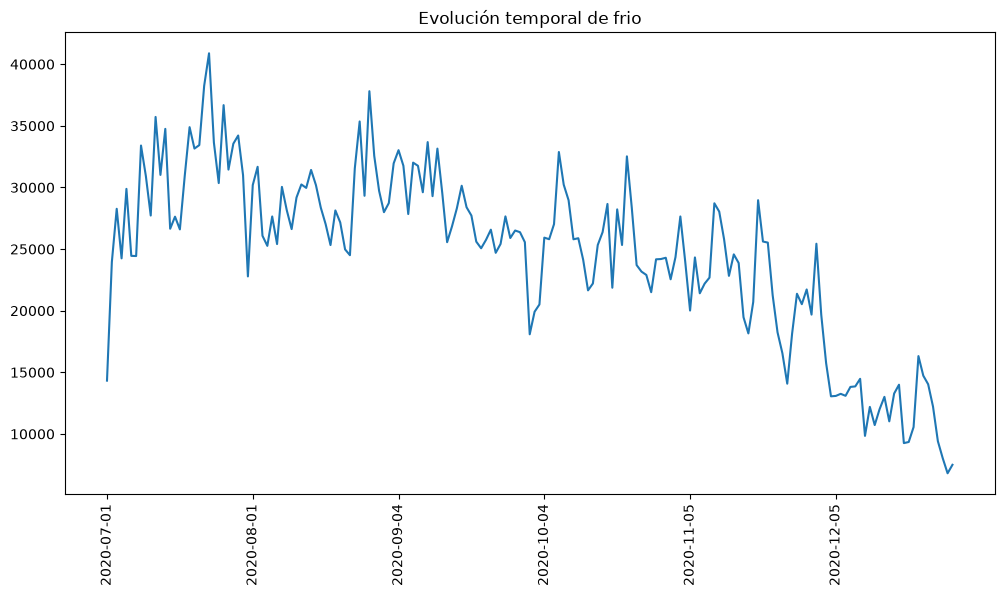

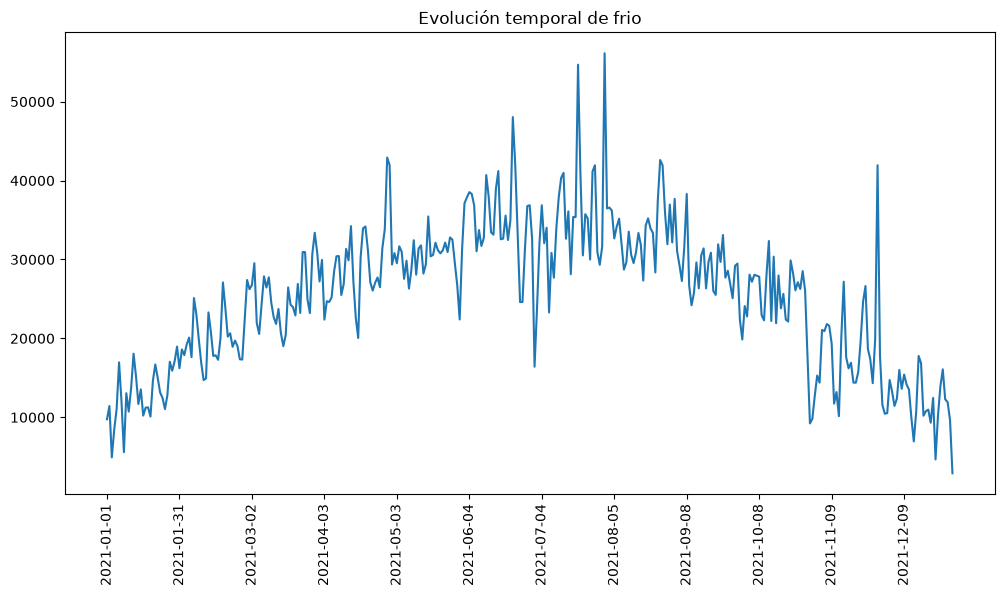

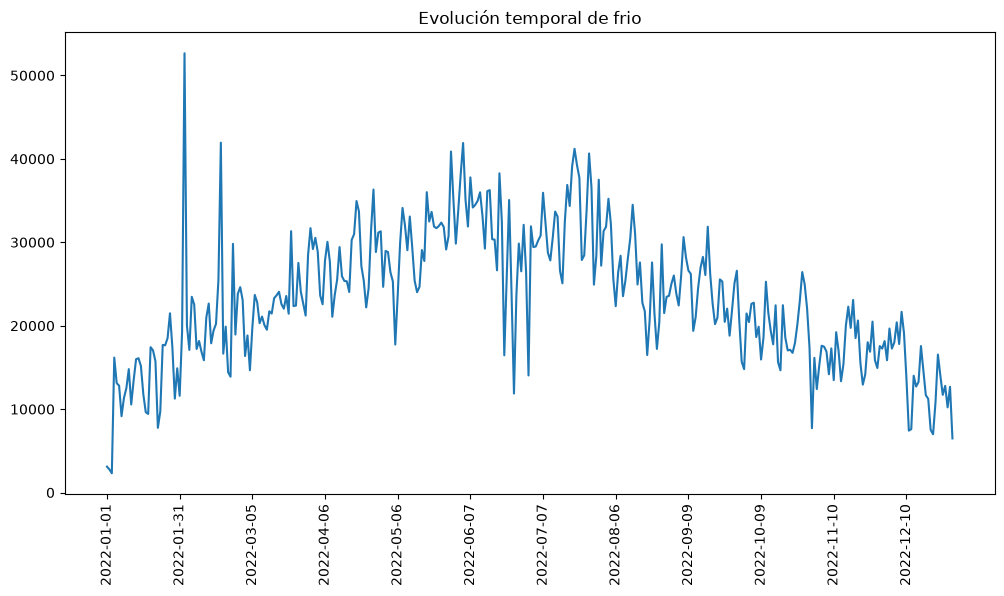

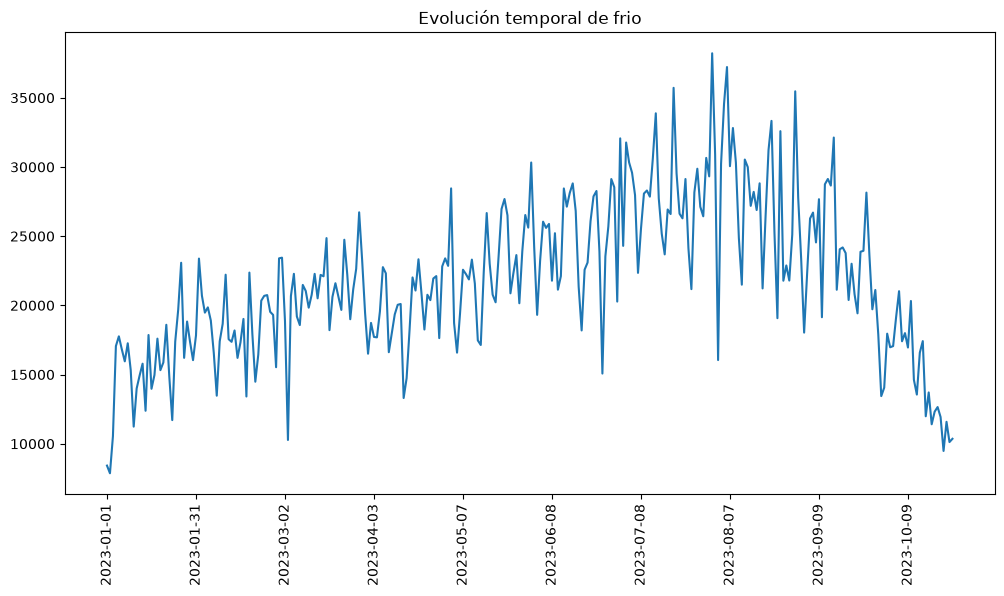

In [178]:
anios = ["2020","2021","2022","2023"]
for anio in anios:
    df_anio = df_completo_sin_outliers[df_completo_sin_outliers["DIA"].str.contains(anio)]
    plt.figure(figsize=(12,6))
    plt.plot(df_anio["DIA"], df_anio["Frio (Kw)"])
    plt.xticks(df_anio["DIA"][::30],rotation=90)
    plt.title("Evolución temporal de frio")
    plt.show()

se puede observar estacionariedad

In [179]:
df_completo_sin_outliers["DIA"] = pd.to_datetime(df_completo_sin_outliers["DIA"])
df_completo_sin_outliers["DIA SEMANA"] = df_completo_sin_outliers["DIA"].dt.dayofweek

C:\Users\ireni\AppData\Local\Temp\ipykernel_43160\1194013341.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_completo_sin_outliers["DIA SEMANA"] = df_completo_sin_outliers["DIA"].dt.dayofweek


<Axes: xlabel='DIA SEMANA', ylabel='target_Frio_kW_next'>

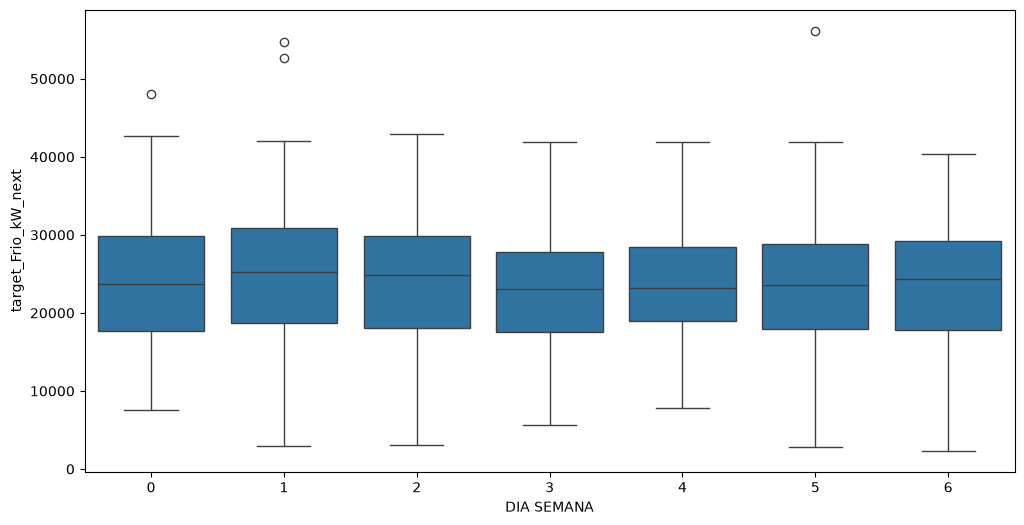

In [180]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_completo_sin_outliers, x="DIA SEMANA",y= "target_Frio_kW_next")


Descartamos la idea de añadir la columna de "DIA SEMANA" ya que no se observa efectos apreciables para cada día o algún día específico.

In [181]:
df_completo_sin_outliers = df_completo_sin_outliers.drop(columns="DIA SEMANA")

## ANÁLISIS DE CORRELACIONES

<Axes: >

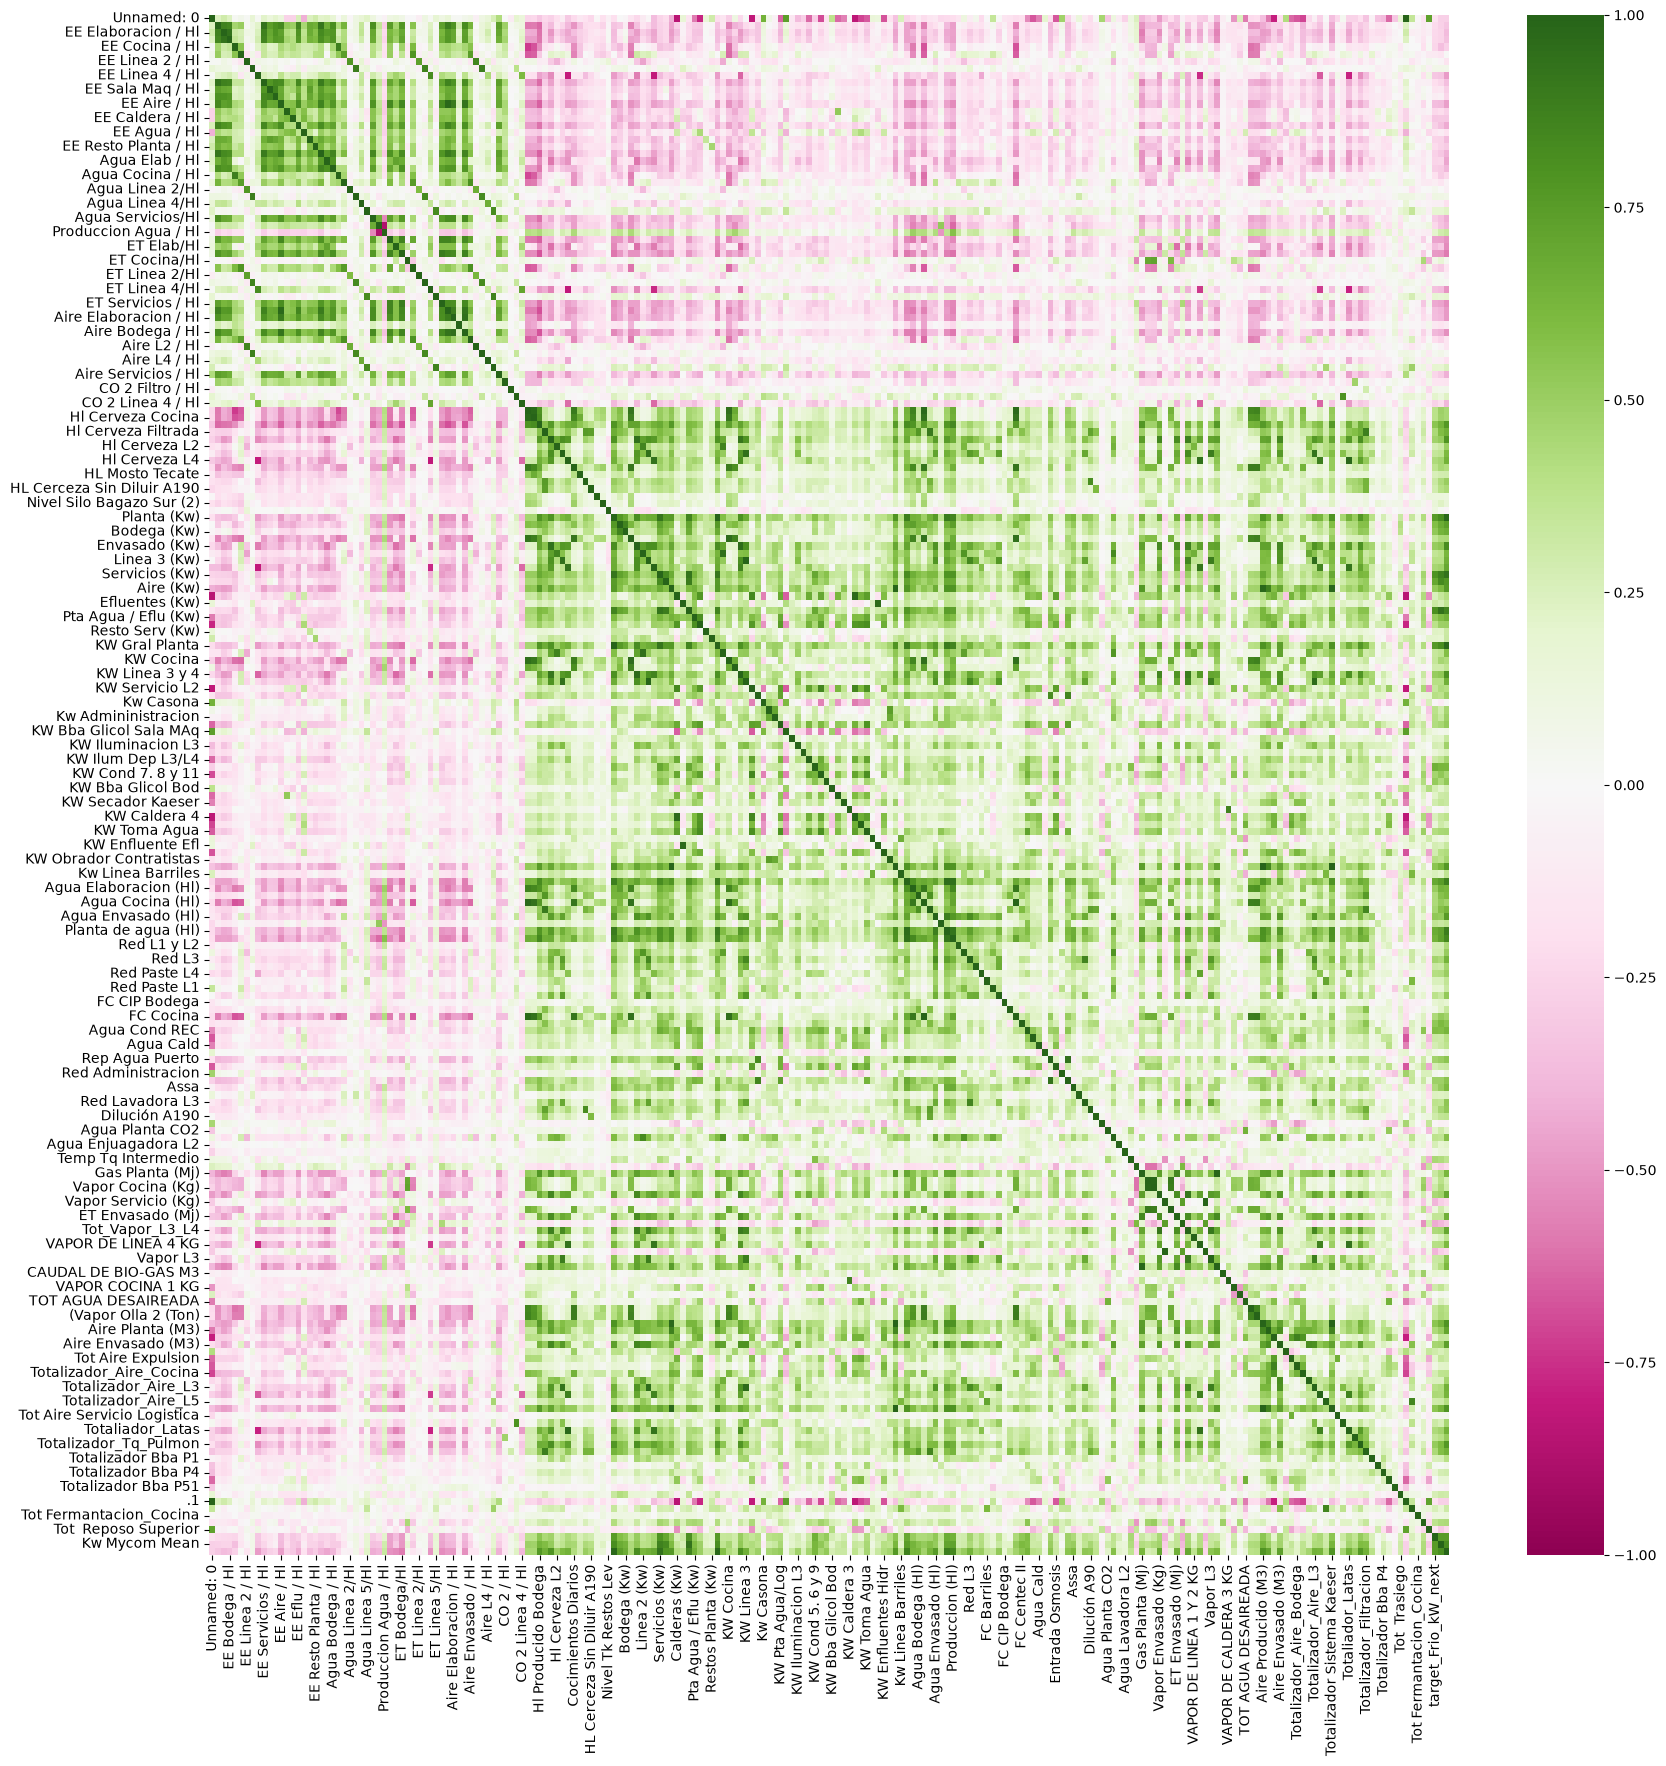

In [182]:
mtx_correlacion = df_completo_sin_outliers[features_sin_dia].corr() 
plt.figure(figsize=(20,20))
sns.heatmap(data=mtx_correlacion, cmap="PiYG",vmin=-1, vmax=1)


In [183]:
display(mtx_correlacion["target_Frio_kW_next"])

Unnamed: 0             -0.174362
EE Planta / Hl         -0.222850
EE Elaboracion / Hl    -0.229856
EE Bodega / Hl         -0.240618
EE Cocina / Hl         -0.242760
                          ...   
Tot Reposo Inferior     0.378167
Tot  Reposo Superior   -0.160475
target_Frio_kW_next     1.000000
Kw Mycom Mean           0.750891
Kw Trafo Mean           0.754762
Name: target_Frio_kW_next, Length: 216, dtype: float64

In [184]:
df_sin_frio_outliers.columns

Index(['DIA', 'EE Frio / Hl', 'KW Bba Glicol Sala MAq', 'KW Bba Glicol Bod',
       'KW Enfr Agua Cocina', 'Hl de Mosto', 'Hl Producido Bodega',
       'Hl Cerveza Filtrada', 'Hl Cerveza Envasada', 'Hl Cerveza Cocina',
       'Elaboracion (Kw)', 'Bodega (Kw)', 'Envasado (Kw)', 'Servicios (Kw)',
       'Frio (Kw)', 'Agua Planta (Hl)', 'Agua Helada Cocina',
       'Glicol Paste L3', 'Temp Tq Intermedio', 'Gas Planta (Mj)',
       'Vapor Elaboracion (Kg)', 'Totalizador_Bodega', 'Totalizador_Tq_Pulmon',
       'Tot Fermantacion_Cocina', 'Tot Reposo Inferior',
       'Tot  Reposo Superior', 'Tot  Trasiego', 'Tot A10/20',
       'Tot A40/240/50/60/Centec/Filtro', 'Tot  A130/330/430',
       'Tot L3, L4 y Planta de CO2', 'target_Frio_kW_next', 'Kw Mycom Mean'],
      dtype='str')

In [185]:
columns_corr_target =mtx_correlacion["target_Frio_kW_next"].abs().sort_values(ascending=False).index[1:16]
columns_corr_target

Index(['Frio (Kw)', 'Servicios (Kw)', 'KW Gral Planta', 'Planta (Kw)',
       'Kw Trafo Mean', 'Kw Mycom Mean', 'Sala Maq (Kw)', 'Agua Planta (Hl)',
       'Planta de agua (Hl)', 'KW Cond 5. 6 y 9', 'Produccion (Hl)',
       'Agua Cond REC', 'Elaboracion (Kw)', 'Aire Producido (M3)',
       'Totalizador Sistema Kaeser'],
      dtype='str')

In [186]:
mtx_correlacion_spearman = df_completo_sin_outliers[features_sin_dia].corr(method="spearman") 
columns_corr_target_spearman = mtx_correlacion_spearman["target_Frio_kW_next"].abs().sort_values(ascending=False).index[1:16]
columns_corr_target_spearman

Index(['Frio (Kw)', 'Servicios (Kw)', 'Sala Maq (Kw)', 'KW Gral Planta',
       'Planta (Kw)', 'Kw Trafo Mean', 'Kw Mycom Mean', 'Agua Planta (Hl)',
       'Planta de agua (Hl)', 'ET Bodega/Hl', 'KW Cond 5. 6 y 9',
       'ET Servicios / Hl', 'Produccion (Hl)', 'Agua Cond REC',
       'Aire Producido (M3)'],
      dtype='str')

<Axes: >

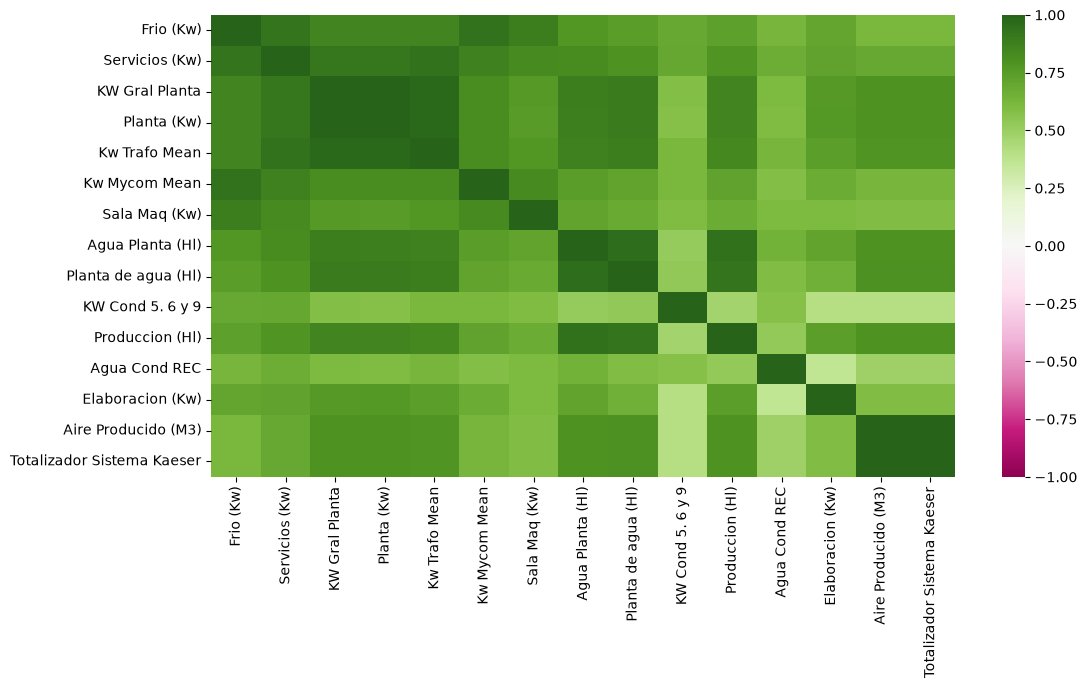

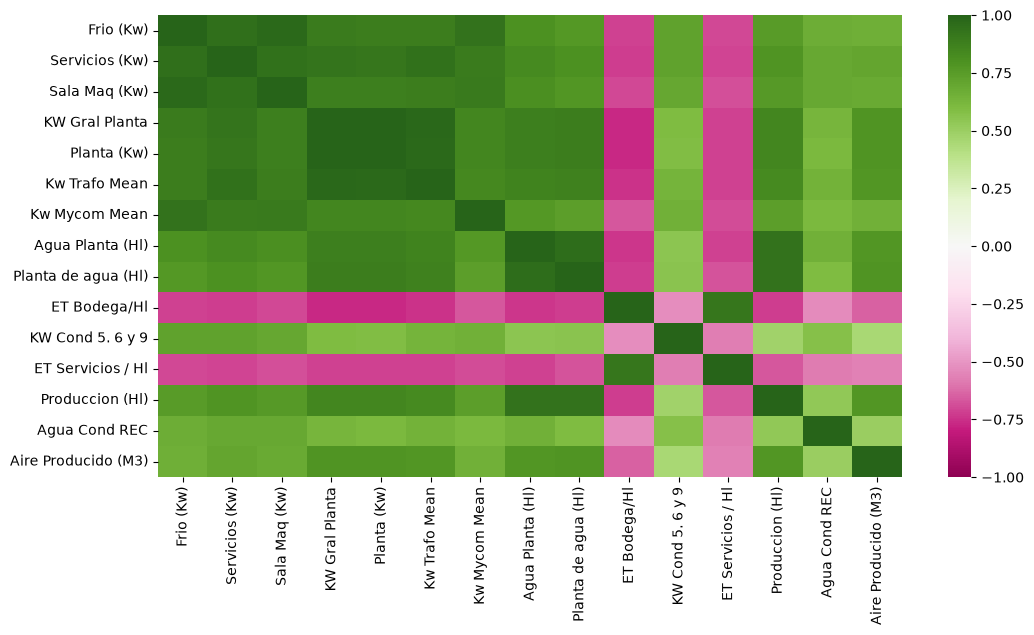

In [187]:
mtx_15_corr_pearson = df_completo_sin_outliers[columns_corr_target].corr()
plt.figure(figsize=(12,6))
sns.heatmap(data=mtx_15_corr_pearson, cmap="PiYG",vmin=-1, vmax=1)

mtx_15_corr_spearman = df_completo_sin_outliers[columns_corr_target_spearman].corr(method="spearman")
plt.figure(figsize=(12,6))
sns.heatmap(data=mtx_15_corr_spearman, cmap="PiYG",vmin=-1, vmax=1)


### Visualizaciones Requeridas

<Axes: xlabel='DIA', ylabel='target_Frio_kW_next'>

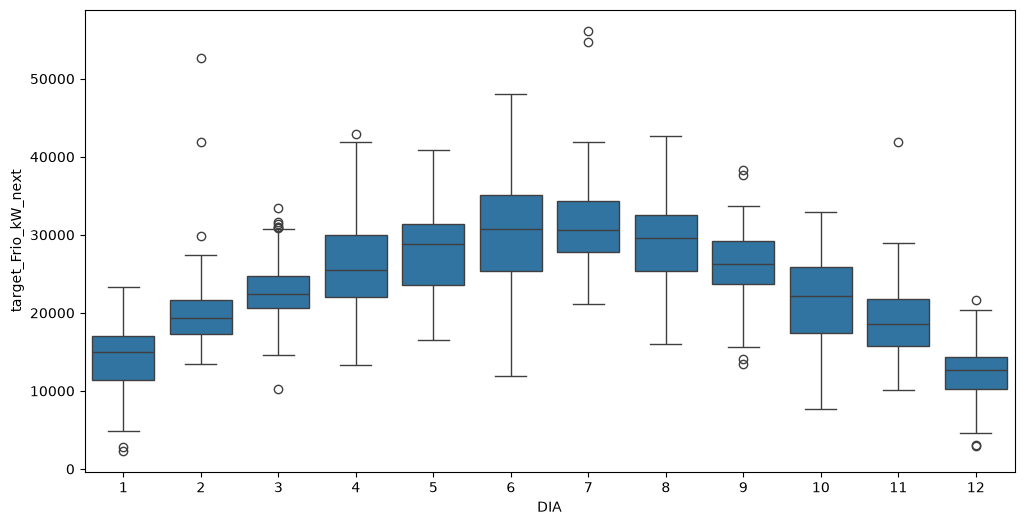

In [188]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_completo_sin_outliers, x=df_completo_sin_outliers["DIA"].dt.month, y= "target_Frio_kW_next")

Se observa que en los meses en donde es verano (Mexico) hay mayor consumo de Frío 

<Axes: xlabel='target_Frio_kW_next', ylabel='Count'>

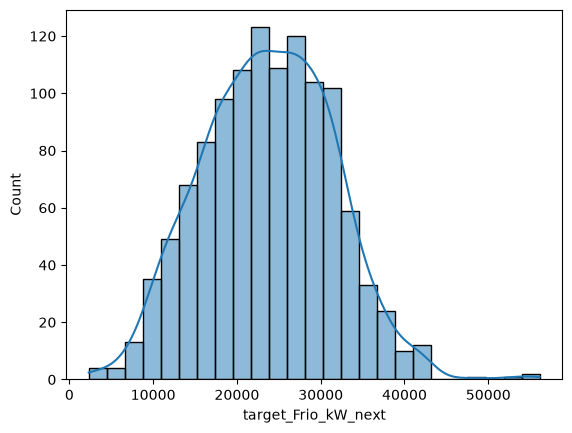

In [189]:
sns.histplot(data=df_completo_sin_outliers, x="target_Frio_kW_next", kde=True)

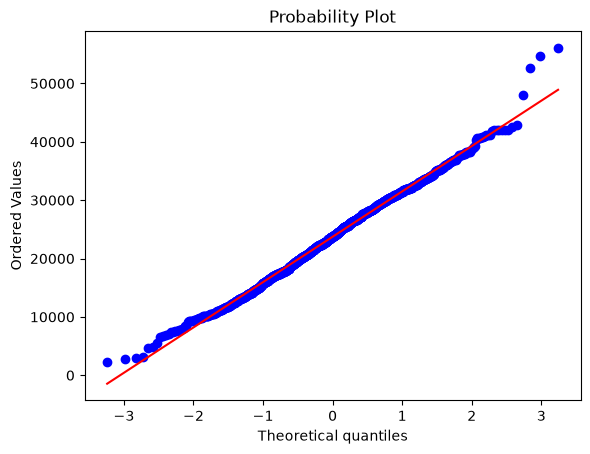

In [190]:
stats.probplot(df_completo_sin_outliers["target_Frio_kW_next"], plot=plt)
plt.show()

Se observa que la target tiene una distribución aproximadamente normal

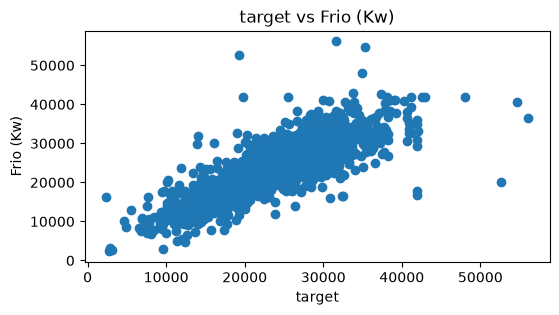

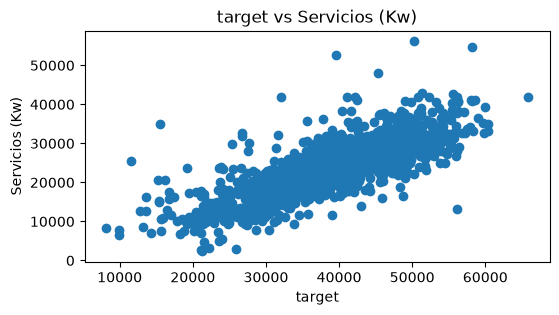

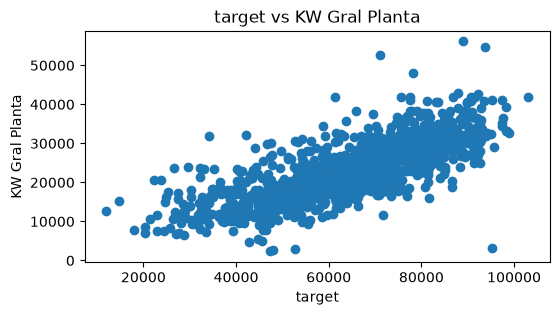

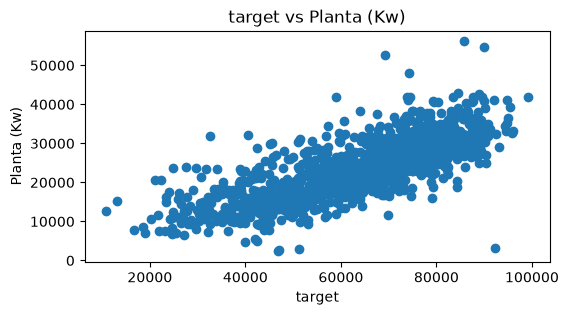

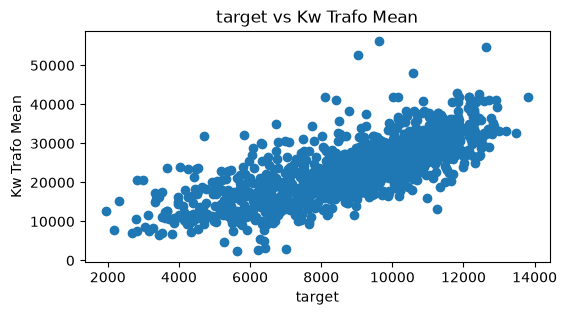

In [191]:
#columns_corr_target_spearman
#columns_corr_target

for c in columns_corr_target[:5]:
    plt.figure(figsize=(6,3))
    plt.scatter(x=df_completo_sin_outliers[c], y=df_completo_sin_outliers["target_Frio_kW_next"])
    plt.title(f"target vs {c}")
    plt.ylabel(c)
    plt.xlabel("target")

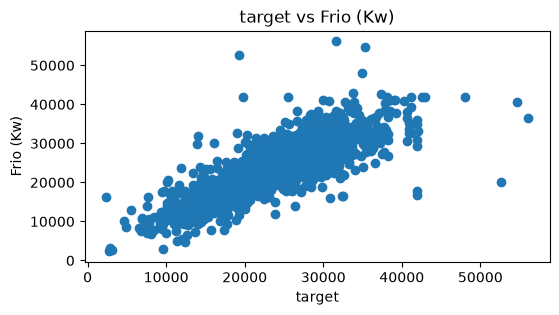

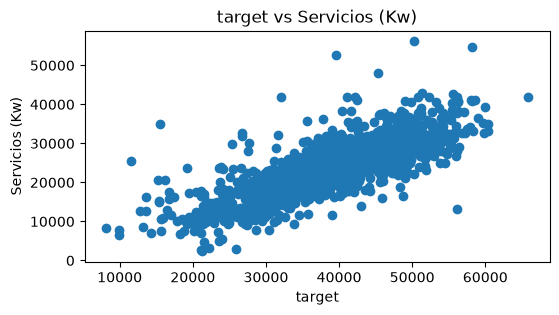

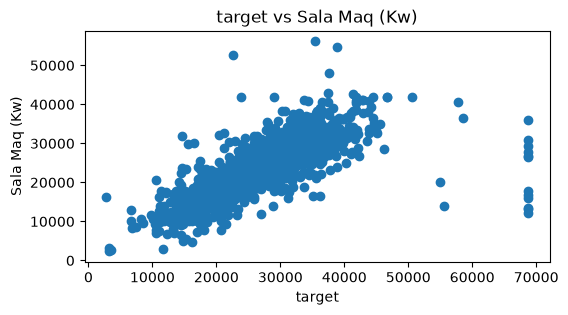

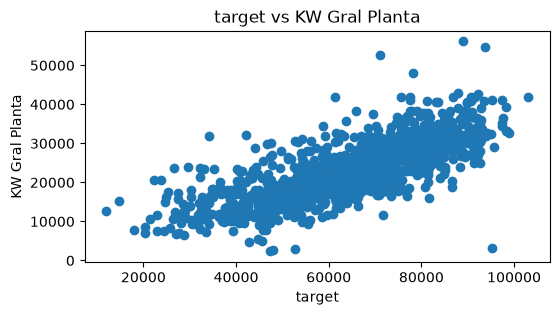

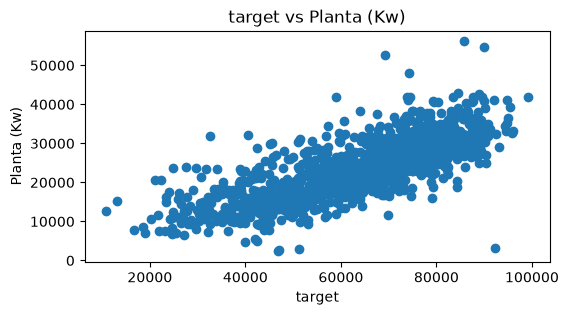

In [192]:

for c in columns_corr_target_spearman[:5]:
    plt.figure(figsize=(6,3))
    plt.scatter(x=df_completo_sin_outliers[c], y=df_completo_sin_outliers["target_Frio_kW_next"])
    plt.title(f"target vs {c}")
    plt.ylabel(c)
    plt.xlabel("target")

<Axes: >

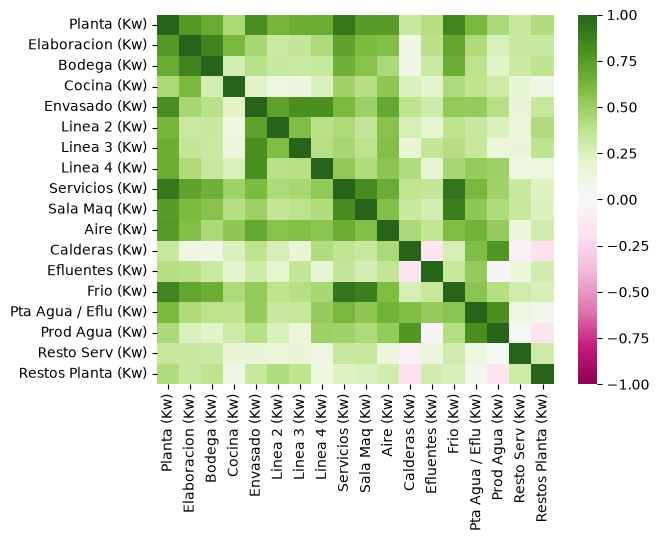

In [193]:
areas = df_completo_sin_outliers.columns[df_completo_sin_outliers.columns.str.contains("\\(Kw\\)")] #Sin los \\ lo toma como expresión regular y no encuentra nada, por eso hay que escaparlos.
mtx_areas_corr = df_completo_sin_outliers[areas].corr()
sns.heatmap(data=mtx_areas_corr, cmap="PiYG",vmin=-1, vmax=1)#annot=True, fmt=".2f")

<Axes: >

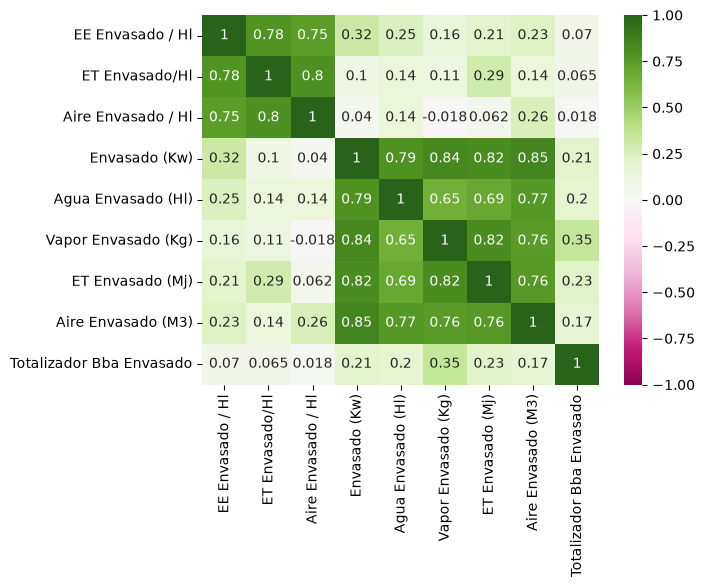

In [194]:
envasados = df_completo_sin_outliers.columns[df_completo_sin_outliers.columns.str.contains("Envasado")]
mtx_envasados_corr = df_completo_sin_outliers[envasados].corr()
sns.heatmap(data=mtx_envasados_corr, cmap="PiYG",vmin=-1, vmax=1,annot=True)

### CONCLUSIONES:

* Se presentaron una gran cantidad de variables con valores nulos y valores cero, incluso superando el 50%.
* No se observo influencia del día de la semana en el consumo de frío.
* Se observo outliers extremos del orden de millones en varias variables.
* Se observo estacionariedad mensual: en los meses de verano hay un mayor consumo de frío.
* Se añadieran nuevas variables al dataset consolidados tras realizar un analisis en el dataset completo. 